
## Predicting Bestselling Books for a Book Press Using E-commerce Product Data

---

| | |
|:---|:---|
| **Dataset** | Amazon Products Dataset 2023 (1.4M Products) |
| **Source** | https://www.kaggle.com/datasets/asaniczka/amazon-products-dataset-2023-1-4m-products |

---

| | |
|:---|:---|
| **Module Code** | PDAN8412 |
| **Module Name** | Programming for Data Analytics 2 |
| **Assessment** | Part 2, Logistic Regression |
| **Academic Year** | 2026 |

---

| | |
|:---|:---|
| **Student Name** | Khodani Mbovane |
| **Student No.** | ST10524773 |
| **Qualification** | Postgraduate Diploma in Data Analytics (NQF 8) |
| **Institution** | The Independent Institute of Education (IIE) / EMERIS |
| **Submission** | 21 October 2026 |

---

**Declaration**

I declare that this assignment is my own original work. All sources have been acknowledged using the Harvard referencing style. No part of this submission has been copied from any other source without proper acknowledgement.

**Signed:** K. Mbovane &nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; **Date:** 21 October 2026

## Table of Contents

1. **Reason for Data Selection**
   - 1.1 Industry Acknowledgement
   - 1.2 Suitability Against the Client Brief
2. **Planning Stage**
   - 2.1 End-to-End Plan Table
   - 2.2 Planned Hyperparameters
   - 2.3 Planned Evaluation Metrics
   - 2.4 Additional Considerations
   - 2.5 Report Plan
3. **Conducting My Analysis**
   - 3.1 Environment Setup and Data Loading
   - 3.2 Initial Data Inspection
   - 3.3 Filtering to Book Categories
   - 3.4 Data Cleaning
   - 3.5 Exploratory Visualisation
   - 3.6 Feature Engineering
   - 3.7 Sampling and Splitting the Data
   - 3.8 Feature Selection
   - 3.9 Training the Model from Scratch
4. **Model Evaluation and Interpretation**
   - 4.1 Baseline Evaluation
   - 4.2 Retraining with Different Parameters
   - 4.3 Final Evaluation on the Test Set
   - 4.4 Confusion Matrix and ROC Curve
   - 4.5 Overfitting Check
   - 4.6 Interpreting the Coefficients
   - 4.7 Library-Based Evaluation and Benchmark
5. **Report for the Client**
6. **Conclusion**
7. **Reference List**

## 1 Reason for Data Selection

Upon reviewing the Amazon Products Dataset, it became evident that it is appropriate for the task the book press has set, which is to predict whether a book will become a bestseller. The dataset, published on Kaggle, contains over one million Amazon products together with the price, list price, star rating, number of reviews, category and an `isBestSeller` flag for each product (Asaniczka, 2023). Because the bestseller label already exists, I do not have to invent a target variable, and the problem maps directly onto a supervised binary classification task suited to logistic regression (Hosmer, Lemeshow and Sturdivant, 2013).

The variables included are purposeful and relevant to the client. The category field allows me to filter the data down to book categories, which keeps the analysis in the client's domain. Price, list price, star rating and review count give me numeric predictors, and the category gives me a categorical predictor. From a data quality perspective, several preparation steps will be necessary before modelling. Some products have a price of zero, many have no reviews, and duplicate product identifiers may exist. The target is also expected to be heavily imbalanced, because bestsellers are rare by definition, which means accuracy alone will not be a reliable measure of success (He and Garcia, 2009).

Certain limitations are worth acknowledging. The data is a single snapshot from one platform, so it does not describe sales over time and may not generalise to other retailers. Star ratings and review counts only exist after a book has been on sale, which means the model is best described as an early-signal model and not a pre-launch forecast. The dataset also includes a units-bought-last-month field that is closely tied to bestseller status, and using it as a predictor would introduce target leakage (Kaufman et al., 2012). I test this in the EDA and exclude the field on purpose. Finally, the dataset has no author, publisher, page count or publication date, so content-based drivers of bestseller status cannot be captured.

> The dataset is openly available, requires no scraping, and contains product-level information only. No personally identifiable information enters the analysis, so there is no POPIA exposure to manage in this notebook (Republic of South Africa, 2013).

### 1.1 Industry Acknowledgement

The dataset sits in e-commerce and publishing, while my own day-to-day work is in finance. I still consider it appropriate because the analytical structure is the same as problems I meet in finance. In both cases the business wants to predict a rare, high-value outcome from a handful of numeric and categorical variables, and the rare class makes plain accuracy misleading. A bestseller flag behaves like a fraud flag or a default flag, so the same discipline around class imbalance, leakage and metric choice applies.

### 1.2 Suitability Against the Client Brief

| Requirement | How the dataset meets it |
|:---|:---|
| Source my own dataset | Public Kaggle dataset, sourced and referenced by me |
| Predict bestsellers | Built-in `isBestSeller` target |
| Suitable size | Over one million rows before filtering, checked against the 10,000 row minimum after filtering and cleaning in section 3 |
| Quality | Missing values, zero prices, zero reviews and duplicates are all checked and treated in section 3 |
| Domain fit | Category field allows filtering to books |

## 2 Planning Stage

The plan below maps each stage of the analysis to its purpose and tooling. It is kept short on purpose, and the detail is shown in the sections that follow.

### 2.1 End-to-End Plan Table

| **Stage** | **What Will Be Done** | **Tool / Method** |
|:---|:---|:---|
| **1. Setup and Loading** | Import libraries, load the products and categories files, and merge them on category ID | pandas |
| **2. EDA** | Check shape, data types, missing values, duplicates, zero prices and outliers. Filter to book categories | pandas, seaborn, matplotlib |
| **3. Data Cleaning** | Drop duplicates, treat zero prices, flag unrated books, convert the target to 0 and 1 | pandas |
| **4. EDA Visuals** | Plot class balance, distributions by class, bestseller rate by price and review band, a leakage check and a correlation heatmap | seaborn, matplotlib |
| **5. Feature Engineering** | Create log price, log reviews, discount percentage, flags and category dummies | pandas, numpy |
| **6. Sampling and Split** | Take a stratified sample, then split 70/15/15 into train, validation and test | sklearn |
| **7. Feature Selection** | Standardise on training data, check VIF, then apply backward elimination at p > 0.05 with forward selection as a cross-check | statsmodels |
| **8. Model Training** | Train logistic regression written from scratch with gradient descent | numpy |
| **9. Evaluation and Retraining** | Evaluate the baseline, then retrain using class weights, L2 and a tuned threshold, and compare | numpy, pandas |
| **10. Interpretation** | Interpret coefficients as odds ratios and check for overfitting | numpy, matplotlib |
| **11. Report** | Summarise cleaning, EDA, training, evaluation and limitations for the client | Markdown |

### 2.2 Planned Hyperparameters

| **Hyperparameter** | **Baseline (Model 1)** | **Tuned (Model 2)** | **Reason** |
|:---|:---|:---|:---|
| Learning rate | 0.1 | 0.05, 0.1, 0.5 | Controls the step size of gradient descent |
| Iterations | 2000 | 2000 | Enough for the cost to flatten out |
| L2 penalty | 0 | 0, 1, 10 | Reduces overfitting and stabilises coefficients |
| Class weight | None | Balanced | Stops the model ignoring the rare bestseller class |
| Threshold | 0.5 | Tuned on validation | 0.5 is rarely best when the positive class is rare |

### 2.3 Planned Evaluation Metrics

| **Metric** | **Why It Is Used** |
|:---|:---|
| Confusion matrix | Shows the exact mix of correct and incorrect predictions |
| Precision | Of the books predicted as bestsellers, how many really were |
| Recall | Of the real bestsellers, how many the model found |
| F1 score | Balances precision and recall, used to choose the final model |
| ROC-AUC | Measures how well the model ranks bestsellers above non-bestsellers, independent of threshold (Fawcett, 2006) |
| Accuracy | Reported for completeness but not relied on, because of class imbalance (Saito and Rehmsmeier, 2015) |
| Precision-recall curve | Shows performance on the rare class without being inflated by the many true negatives (Saito and Rehmsmeier, 2015) |

### 2.4 Additional Considerations

| **Consideration** | **Planned Action** | **Reason** |
|:---|:---|:---|
| Target leakage | Test `boughtinlastmonth` and exclude it if it gives away the target | A press would not know it before launch (Kaufman et al., 2012) |
| Class imbalance | Class weights, tuned threshold and imbalance-aware metrics | Bestsellers are rare (He and Garcia, 2009) |
| Leakage between data splits | Stratified split, scaling fitted on training data only, test set used once | Keeps the final score honest |
| Multicollinearity | VIF check before elimination | Redundant features inflate coefficient variance (O'Brien, 2007) |
| Stability of feature selection | Backward elimination as the main method, forward selection as a cross-check | Confirms the chosen features are not an accident of one method |
| Convergence | Plot the cost curve | Confirms gradient descent has settled |
| Correctness of my own code | Cross-check coefficients and metrics against scikit-learn | Proves the from-scratch model is right |
| Computation time | Stratified sample capped at 100,000 rows | Keeps from-scratch training practical |

### 2.5 Report Plan

| **Report Section** | **Content** |
|:---|:---|
| Data and cleaning | Source, size before and after, issues found and how each was treated |
| EDA | Class balance, patterns by price, reviews and category, with visuals |
| Model training | Features used, hyperparameters, cost curve |
| Evaluation | Metrics, confusion matrix, ROC and precision-recall curves, baseline against tuned model |
| Accuracy and effectiveness | Validation and test discipline, library cross-check, overfitting check |
| Recommendations and limitations | What the press should do with the model and what it cannot do |

# 3 Conducting My Analysis

## 3.1 Environment Setup and Data Loading

The libraries used are pandas (McKinney, 2010), NumPy (Harris et al., 2020), Matplotlib (Hunter, 2007), seaborn (Waskom, 2021), statsmodels (Seabold and Perktold, 2010) and scikit-learn (Pedregosa et al., 2011). The logistic regression itself is written with NumPy only. Scikit-learn is used for splitting the data and for independently checking my own results.

In [1]:
# Loading libraries
import os                                         # File handling
import glob                                       # Finding files
import shutil                                     # Copying files
import subprocess                                 # Running the Kaggle download
import zipfile                                    # Unzipping the download
import numpy as np                                # Maths functions and arrays
import pandas as pd                               # For data analysis
import matplotlib.pyplot as plt                   # Plotting
import seaborn as sns                             # Plotting
import statsmodels.api as sm                      # P-values for feature selection
from statsmodels.stats.outliers_influence import variance_inflation_factor   # VIF check
from IPython.display import Markdown, display     # Showing comments written from the results
import warnings
warnings.filterwarnings("ignore")

# Sklearn is only used for splitting the data and cross-checking my own results
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix as sk_confusion_matrix, roc_auc_score

# Fixing the random seed so the results can be reproduced
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Keeping the plots simple
sns.set_style("whitegrid")

def say(text):
    # Showing a comment that is written from the real results of the cell above
    display(Markdown(text))

def strength(r):
    # Describing the size of a correlation in words
    a = abs(r)
    return "strong" if a >= 0.5 else "moderate" if a >= 0.3 else "weak"

# Plain-language names for the features, used when talking to the client
PLAIN = {"log_reviews": "number of reviews", "has_reviews": "whether a book has any reviews",
         "stars": "star rating", "log_price": "price", "discount_pct": "discount percentage",
         "has_discount": "whether a discount is offered"}

def plain_name(f):
    return PLAIN.get(f, f.replace("cat_", "category: ").replace("_", " "))

In [2]:
# Setting the Kaggle dataset that is downloaded
KAGGLE_SLUG = "asaniczka/amazon-products-dataset-2023-1-4m-products"

def find_csv(keyword, exclude=None):
    # Searching the working folder for a CSV file whose name contains the keyword
    for f in sorted(glob.glob("**/*.csv", recursive=True)):
        name = os.path.basename(f).lower()
        if keyword in name and (exclude is None or exclude not in name):
            return f
    return None

def unzip_all():
    # Unzipping any downloaded zip files in the working folder
    for z in glob.glob("*.zip"):
        with zipfile.ZipFile(z, "r") as zip_ref:
            zip_ref.extractall()

def download_from_kaggle():
    # Uploading kaggle.json (Kaggle account settings, Create New Token) and downloading with the Kaggle API
    from google.colab import files
    print("Upload your kaggle.json file")
    uploaded = files.upload()
    key_file = [f for f in uploaded if f.endswith(".json")][0]
    kaggle_dir = os.path.expanduser("~/.kaggle")
    os.makedirs(kaggle_dir, exist_ok=True)
    shutil.copy(key_file, os.path.join(kaggle_dir, "kaggle.json"))
    os.chmod(os.path.join(kaggle_dir, "kaggle.json"), 0o600)
    subprocess.run(["kaggle", "datasets", "download", "-d", KAGGLE_SLUG], check=True)

unzip_all()
if find_csv("product", "categor") is None or find_csv("categor") is None:
    try:
        download_from_kaggle()
    except Exception as err:
        # Falling back to uploading the two CSV files by hand
        print("Automatic download did not work:", err)
        print("Upload the products CSV and the categories CSV from the Kaggle page instead")
        from google.colab import files
        files.upload()
    unzip_all()

products_file = find_csv("product", "categor")
categories_file = find_csv("categor")
print("Products file  :", products_file)
print("Categories file:", categories_file)
assert products_file is not None and categories_file is not None, "The two CSV files were not found"

Upload your kaggle.json file


Saving kaggle (2).json to kaggle (2).json
Products file  : amazon_products.csv
Categories file: amazon_categories.csv


In [3]:
# Reading only the columns that are needed, which saves memory on a file this large
header = pd.read_csv(products_file, nrows=0).columns
keep = [c for c in header if c.lower() not in ("title", "imgurl", "producturl")]
products = pd.read_csv(products_file, usecols=keep)
categories = pd.read_csv(categories_file)

# Making all column names lowercase to avoid spelling mistakes later
products.columns = [c.strip().lower() for c in products.columns]
categories.columns = [c.strip().lower() for c in categories.columns]

# Renaming the id column so the two files can be merged on category_id
categories = categories.rename(columns={"id": "category_id"})

# Merging so every product has a readable category name
df = products.merge(categories, on="category_id", how="left")

print("Shape of the full dataset:", df.shape)

Shape of the full dataset: (1426337, 9)


## 3.2 Initial Data Inspection

In [4]:
# Scanning the first 5 rows
df.head()

,asin,stars,reviews,price,listprice,category_id,isbestseller,boughtinlastmonth,category_name
0,B014TMV5YE,4.5,0,139.99,0.00,104,False,2000,Suitcases
1,B07GDLCQXV,4.5,0,169.99,209.99,104,False,1000,Suitcases
2,B07XSCCZYG,4.6,0,365.49,429.99,104,False,300,Suitcases
3,B08MVFKGJM,4.6,0,291.59,354.37,104,False,400,Suitcases
4,B01DJLKZBA,4.5,0,174.99,309.99,104,False,400,Suitcases


In [5]:
# Checking data types and non-null counts
df.info()

# Counting missing values in each column
print("\nMissing values per column:")
print(df.isna().sum())

# Checking for duplicate products using the unique product id (asin)
dup_asin_full = int(df["asin"].duplicated().sum())
print("\nDuplicate asin values:", dup_asin_full)

# Converting the bestseller flag to a share so it is easy to read
share_full = 100 * df["isbestseller"].astype(str).str.lower().isin(["true", "1"]).mean()
print("\nBestseller share (full dataset): {:.2f}%".format(share_full))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1426337 entries, 0 to 1426336
Data columns (total 9 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   asin               1426337 non-null  object 
 1   stars              1426337 non-null  float64
 2   reviews            1426337 non-null  int64  
 3   price              1426337 non-null  float64
 4   listprice          1426337 non-null  float64
 5   category_id        1426337 non-null  int64  
 6   isbestseller       1426337 non-null  bool   
 7   boughtinlastmonth  1426337 non-null  int64  
 8   category_name      1426337 non-null  object 
dtypes: bool(1), float64(3), int64(3), object(2)
memory usage: 88.4+ MB

Missing values per column:
asin                 0
stars                0
reviews              0
price                0
listprice            0
category_id          0
isbestseller         0
boughtinlastmonth    0
category_name        0
dtype: int64

Duplicate asin va

In [6]:
#@title Comment
missing = df.isna().sum()
missing = missing[missing > 0]
if len(missing) > 0:
    missing_text = "Missing values appear in " + ", ".join("`{}` ({:,})".format(c, v) for c, v in missing.items())
else:
    missing_text = "No column contains missing values"

zero_price_full = int((df["price"] == 0).sum())
zero_reviews_full = int((df["reviews"] == 0).sum())
imbalance_text = ("a heavy class imbalance that shapes every later decision" if share_full < 10
                  else "a moderate class imbalance that still needs to be handled")

say(f"""**Comment**

The full dataset has {len(df):,} rows and {df.shape[1]} columns, with {dup_asin_full:,} duplicate `asin` values. {missing_text}. {zero_price_full:,} products have a price of 0 and {zero_reviews_full:,} have no reviews, so zeros must be treated before these columns are used. Bestsellers make up only {share_full:.2f}% of all products, which signals {imbalance_text}.""")

**Comment**

The full dataset has 1,426,337 rows and 9 columns, with 0 duplicate `asin` values. No column contains missing values. 32,772 products have a price of 0 and 1,130,503 have no reviews, so zeros must be treated before these columns are used. Bestsellers make up only 0.60% of all products, which signals a heavy class imbalance that shapes every later decision.

## 3.3 Filtering to Book Categories

The client is a book press, so book-related categories are used. A filter is only accepted if it leaves at least 10,000 rows and at least 100 bestsellers, which is the least needed to train and test a classifier on a rare class.

In [7]:
def book_filter(keywords):
    # Keeping rows where the category name contains any of the keywords
    pattern = "|".join(keywords)
    return df["category_name"].str.contains(pattern, case=False, na=False)

# Marking which products are bestsellers so each candidate filter can be checked
is_best_all = df["isbestseller"].astype(str).str.lower().isin(["true", "1"])

# A filter is only accepted if it leaves enough rows and enough bestsellers
MIN_ROWS = 10000
MIN_BESTSELLERS = 100

candidates = [
    ("book categories", ["book"]),
    ("book and reading-related categories",
     ["book", "kindle", "audible", "audiobook", "magazine", "comic", "novel", "literat"]),
]

# Starting from all categories and keeping the first candidate that passes both checks
filter_level = "all product categories"
book_mask = pd.Series(True, index=df.index)
filter_log = []
for label, keywords in candidates:
    mask = book_filter(keywords)
    filter_log.append((label, int(mask.sum()), int(is_best_all[mask].sum())))
    if mask.sum() >= MIN_ROWS and is_best_all[mask].sum() >= MIN_BESTSELLERS:
        filter_level, book_mask = label, mask
        break

# Showing what each candidate filter returned
for label, n_rows, n_best in filter_log:
    print("{:<40s} rows: {:>9,} | bestsellers: {:>7,}".format(label, n_rows, n_best))
print("\nFilter used:", filter_level)

# Showing the reading-related categories with their sizes and bestseller counts
cat_stats = (
    df.assign(is_best=is_best_all)
    .groupby("category_name")["is_best"]
    .agg(products="count", bestsellers="sum")
    .sort_values("products", ascending=False)
)
reading = cat_stats.index.str.contains("book|kindle|audible|magazine|comic|novel|read|literat", case=False)
print("\nReading-related categories in the dataset:")
print(cat_stats[reading].head(20))

# Printing the categories that are being used
print("\nCategories used (largest 30):")
print(df.loc[book_mask, "category_name"].value_counts().head(30))

books = df[book_mask].copy()
n_books_raw = len(books)
n_book_cats = books["category_name"].nunique()
print("\nShape after filtering:", books.shape)

book categories                          rows:     6,513 | bestsellers:      23
book and reading-related categories      rows:    13,945 | bestsellers:      33

Filter used: all product categories

Reading-related categories in the dataset:
                                  products  bestsellers
category_name                                          
Novelty Toys & Amusements             7432           10
Scrapbooking & Stamping Supplies      5931           22
eBook Readers & Accessories            582            1

Categories used (largest 30):
category_name
Girls' Clothing                                28619
Boys' Clothing                                 24660
Toys & Games                                   20846
Men's Shoes                                    19822
Women's Handbags                               18994
Girls' Jewelry                                 18514
Men's Clothing                                 18258
Men's Accessories                              17679
Women's Cl

In [9]:
#@title Comment
if filter_level == "all product categories":
    first = filter_log[0]
    last = filter_log[-1]
    scope_text = (f"The book categories were too small to train and test a classifier. The word \"book\" alone returned {first[1]:,} rows with {first[2]:,} bestsellers, and the wider reading-related filter returned {last[1]:,} rows with {last[2]:,} bestsellers, against the minimums of {MIN_ROWS:,} rows and {MIN_BESTSELLERS} bestsellers. "
                  "To stay above these minimums I model bestseller status across all product categories. The drivers measured here, which are reviews, rating, price and discount, are not specific to books, so the results are a reasonable proxy for the book press, but they should be confirmed on book data when more of it becomes available. "
                  "For readability, the rest of this notebook still calls each row in the modelled set a book.")
elif filter_level == "book categories":
    scope_text = f"The word \"book\" alone returned enough rows and bestsellers ({n_books_raw:,} rows), so only book categories are used."
else:
    scope_text = f"The word \"book\" alone was too small, so the filter was widened to other reading-related categories (Kindle, audio, magazines, comics and novels), which returned {n_books_raw:,} rows."

say(f"""**Comment**

Filtering reduced the dataset from {len(df):,} rows to {n_books_raw:,} rows across {n_book_cats} categories, which are listed above. {scope_text}""")

**Comment**

Filtering reduced the dataset from 1,426,337 rows to 1,426,337 rows across 248 categories, which are listed above. The book categories were too small to train and test a classifier. The word "book" alone returned 6,513 rows with 23 bestsellers, and the wider reading-related filter returned 13,945 rows with 33 bestsellers, against the minimums of 10,000 rows and 100 bestsellers. To stay above these minimums I model bestseller status across all product categories. The drivers measured here, which are reviews, rating, price and discount, are not specific to books, so the results are a reasonable proxy for the book press, but they should be confirmed on book data when more of it becomes available. For readability, the rest of this notebook still calls each row in the modelled set a book.

## 3.4 Data Cleaning

In [10]:
# 1. Dropping duplicate products so one book is not counted twice
before = len(books)
books = books.drop_duplicates(subset="asin")
dup_removed = before - len(books)
print("Duplicates removed:", dup_removed)

# 2. A price of 0 means no price was captured, so it is treated as missing and dropped
books["price"] = books["price"].replace(0, np.nan)
before = len(books)
books = books.dropna(subset=["price"])
price_dropped = before - len(books)
print("Rows dropped for missing or zero price:", price_dropped)

# 3. A list price of 0 means no original price was shown, so it is set to the price (discount becomes 0)
books["listprice"] = books["listprice"].replace(0, np.nan)
books["listprice"] = books["listprice"].fillna(books["price"])

# 4. Stars and reviews of 0 mean the book is unrated, not badly rated
#    Keeping these rows and adding a flag so the model can tell the difference
books["has_reviews"] = (books["reviews"] > 0).astype(int)
unrated_share = 100 * (1 - books["has_reviews"].mean())

# 5. Converting the target to 0 and 1
books["isbestseller"] = (
    books["isbestseller"].astype(str).str.lower().map({"true": 1, "false": 0, "1": 1, "0": 0})
)
books = books.dropna(subset=["isbestseller"])
books["isbestseller"] = books["isbestseller"].astype(int)

# Making sure there are enough bestsellers to train and test a classifier
if books["isbestseller"].sum() < 100:
    raise ValueError("Fewer than 100 bestsellers remain after cleaning, so the category filter needs to be widened")

n_clean = len(books)
print("\nClean shape:", books.shape)

Duplicates removed: 0
Rows dropped for missing or zero price: 32772

Clean shape: (1393565, 10)


In [11]:
#@title Comment
if n_clean >= 10000:
    clean_size = "which is still above the 10,000 row minimum"
else:
    clean_size = "which is below the 10,000 row minimum, so the results should be read with caution"

say(f"""**Comment**

Cleaning removed {dup_removed:,} duplicate products and {price_dropped:,} rows with no usable price, leaving {n_clean:,} rows, {clean_size}. {unrated_share:.1f}% of the remaining books have no reviews. They were kept and flagged with `has_reviews`, because dropping them would remove a large and meaningful group of products. The target `isbestseller` is now binary, where 1 is a bestseller and 0 is not.""")

**Comment**

Cleaning removed 0 duplicate products and 32,772 rows with no usable price, leaving 1,393,565 rows, which is still above the 10,000 row minimum. 79.2% of the remaining books have no reviews. They were kept and flagged with `has_reviews`, because dropping them would remove a large and meaningful group of products. The target `isbestseller` is now binary, where 1 is a bestseller and 0 is not.

## 3.5 Exploratory Visualisation

isbestseller
0    1385096
1       8469
Name: count, dtype: int64

Bestseller share: 0.61%


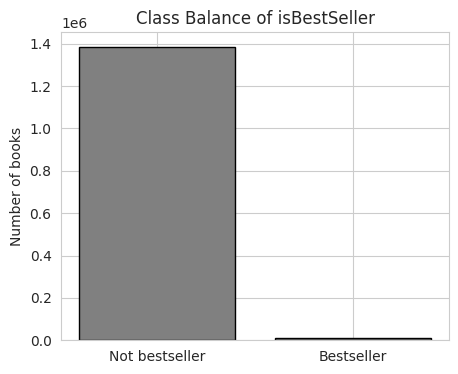

In [12]:
# 1. Class balance of the target
counts = books["isbestseller"].value_counts().sort_index()
print(counts)
share_books = 100 * counts.get(1, 0) / counts.sum()
print("\nBestseller share: {:.2f}%".format(share_books))

plt.figure(figsize=(5, 4))
plt.bar(["Not bestseller", "Bestseller"], counts.values, color="gray", edgecolor="black")
plt.title("Class Balance of isBestSeller")
plt.ylabel("Number of books")
plt.show()

In [13]:
#@title Comment
n_pos = int(counts.get(1, 0))
naive_acc = 100 - share_books

say(f"""**Comment**

Bestsellers make up {share_books:.2f}% of the cleaned books ({n_pos:,} of {counts.sum():,}), so the classes are imbalanced. A model that predicts "not a bestseller" for every book would score an accuracy of {naive_acc:.2f}% while finding no bestsellers at all. This is why precision, recall, F1 and ROC-AUC are used, and why class weights are applied at the retraining stage.""")

**Comment**

Bestsellers make up 0.61% of the cleaned books (8,469 of 1,393,565), so the classes are imbalanced. A model that predicts "not a bestseller" for every book would score an accuracy of 99.39% while finding no bestsellers at all. This is why precision, recall, F1 and ROC-AUC are used, and why class weights are applied at the retraining stage.

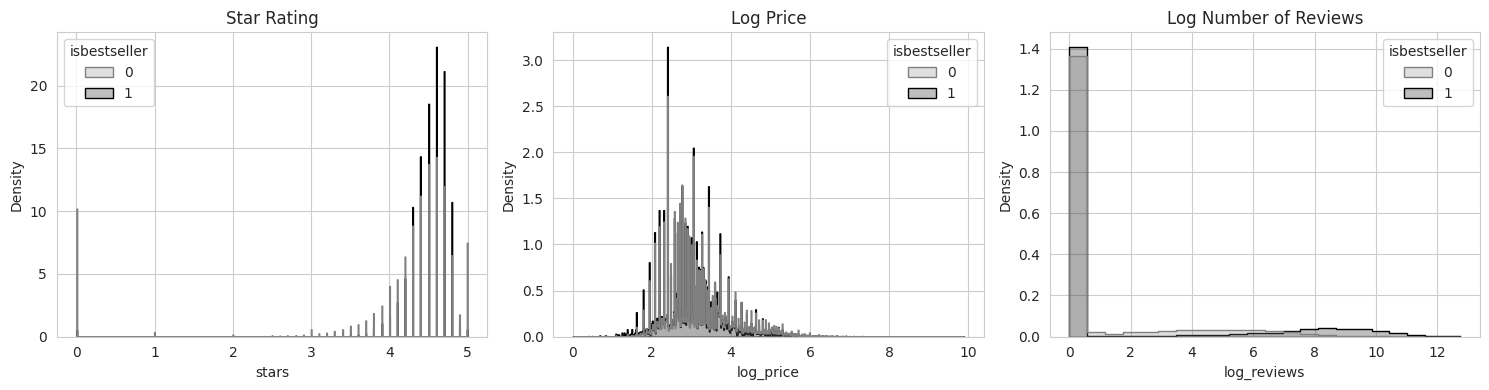

In [14]:
# 2. Distributions of stars, price and reviews by class
# Using log scales for price and reviews because both are heavily right-skewed
books["log_price"] = np.log1p(books["price"])
books["log_reviews"] = np.log1p(books["reviews"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, title in zip(
    axes,
    ["stars", "log_price", "log_reviews"],
    ["Star Rating", "Log Price", "Log Number of Reviews"],
):
    # common_norm=False so each class is scaled on its own and the small class stays visible
    sns.histplot(data=books, x=col, hue="isbestseller", stat="density",
                 common_norm=False, element="step", palette=["gray", "black"], ax=ax)
    ax.set_title(title)
plt.tight_layout()
plt.show()

In [15]:
#@title Comment
g = books.groupby("isbestseller")
med_rev = g["reviews"].median()
mean_stars = g["stars"].mean()
med_price = g["price"].median()

rev_text = "a strong" if med_rev[1] >= 2 * max(med_rev[0], 1) else "a modest"
price_text = "cheaper" if med_price[1] < med_price[0] else "dearer" if med_price[1] > med_price[0] else "the same price"

say(f"""**Comment**

Bestsellers have a median of {med_rev[1]:,.0f} reviews against {med_rev[0]:,.0f} for other books, so review volume looks like {rev_text} signal. The mean star rating is {mean_stars[1]:.2f} for bestsellers against {mean_stars[0]:.2f} for other books, and the median price is {med_price[1]:.2f} against {med_price[0]:.2f}, so bestsellers are typically {price_text}. Log transformations were applied to price and reviews because the raw values are heavily right-skewed, and a skewed predictor can distort gradient descent.""")

**Comment**

Bestsellers have a median of 0 reviews against 0 for other books, so review volume looks like a modest signal. The mean star rating is 4.49 for bestsellers against 4.00 for other books, and the median price is 18.49 against 19.99, so bestsellers are typically cheaper. Log transformations were applied to price and reviews because the raw values are heavily right-skewed, and a skewed predictor can distort gradient descent.

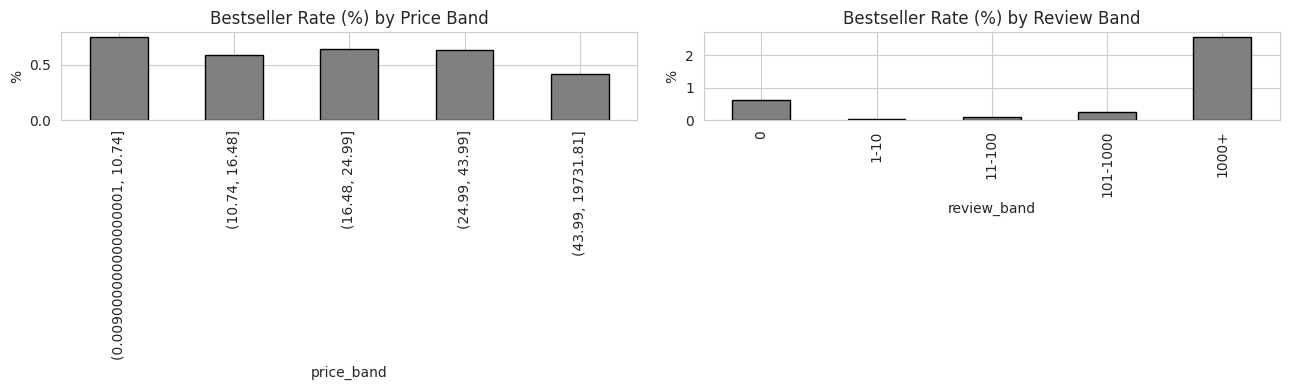

In [16]:
# 3. Bestseller rate by price band and review band
# Splitting price into 5 equal-sized bands
books["price_band"] = pd.qcut(books["price"], 5, duplicates="drop")
price_rate = books.groupby("price_band", observed=True)["isbestseller"].mean() * 100

# Splitting reviews into fixed bands that are easy to explain
review_bins = [-1, 0, 10, 100, 1000, np.inf]
review_labels = ["0", "1-10", "11-100", "101-1000", "1000+"]
books["review_band"] = pd.cut(books["reviews"], bins=review_bins, labels=review_labels)
review_rate = books.groupby("review_band", observed=True)["isbestseller"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
price_rate.plot(kind="bar", color="gray", edgecolor="black", ax=axes[0])
axes[0].set_title("Bestseller Rate (%) by Price Band")
axes[0].set_ylabel("%")
review_rate.plot(kind="bar", color="gray", edgecolor="black", ax=axes[1])
axes[1].set_title("Bestseller Rate (%) by Review Band")
axes[1].set_ylabel("%")
plt.tight_layout()
plt.show()

In [17]:
#@title Comment
rr = review_rate.dropna()
pr = price_rate.dropna()
rising = bool((rr.diff().dropna() >= 0).all())
rise_text = "rising with every band" if rising else "although the rise is not steady across every band"
price_diff = "a clear" if pr.max() > 2 * max(pr.min(), 0.01) else "little"

say(f"""**Comment**

The bestseller rate moves from {rr.iloc[0]:.2f}% in the lowest review band ({rr.index[0]}) to {rr.iloc[-1]:.2f}% in the highest ({rr.index[-1]}), {rise_text}. Across the five price bands the rate ranges from {pr.min():.2f}% to {pr.max():.2f}%, so price shows {price_diff} difference. This tells me which predictors are likely to survive feature selection and which will add little.""")

**Comment**

The bestseller rate moves from 0.63% in the lowest review band (0) to 2.57% in the highest (1000+), although the rise is not steady across every band. Across the five price bands the rate ranges from 0.42% to 0.76%, so price shows little difference. This tells me which predictors are likely to survive feature selection and which will add little.

In [18]:
# 4. Leakage check on boughtinlastmonth
bought_flag = books["boughtinlastmonth"].fillna(0) > 0
rate_bought = 100 * books.loc[bought_flag, "isbestseller"].mean() if bought_flag.any() else 0.0
rate_not_bought = 100 * books.loc[~bought_flag, "isbestseller"].mean()
print("Bestseller rate when bought in last month > 0:  {:.2f}%".format(rate_bought))
print("Bestseller rate when bought in last month == 0: {:.2f}%".format(rate_not_bought))

Bestseller rate when bought in last month > 0:  1.34%
Bestseller rate when bought in last month == 0: 0.19%


In [19]:
#@title Comment
gap_text = ("a gap this large shows that the field is closely tied to the target" if rate_bought > 3 * max(rate_not_bought, 0.01)
            else "the gap is smaller, but the field is still unavailable before a book is launched")

say(f"""**Comment**

The bestseller rate is {rate_bought:.2f}% when `boughtinlastmonth` is above zero and {rate_not_bought:.2f}% when it is zero. Here, {gap_text} (Kaufman et al., 2012). A book press would also not know this value before a book sells. I have therefore decided to exclude `boughtinlastmonth` from the model, as keeping it would give an unrealistically good result.""")

**Comment**

The bestseller rate is 1.34% when `boughtinlastmonth` is above zero and 0.19% when it is zero. Here, a gap this large shows that the field is closely tied to the target (Kaufman et al., 2012). A book press would also not know this value before a book sells. I have therefore decided to exclude `boughtinlastmonth` from the model, as keeping it would give an unrealistically good result.

                   books  bestseller_rate_%
category_name                              
Girls' Clothing    28289           0.487822
Boys' Clothing     24165           0.417960
Toys & Games       20657           1.161834
Men's Shoes        18780           0.282215
Women's Handbags   18695           0.074886
Girls' Jewelry     18441           0.130145
Men's Clothing     17924           0.647177
Men's Accessories  17482           0.320329
Women's Clothing   17281           0.943232
Women's Jewelry    16948           0.342223


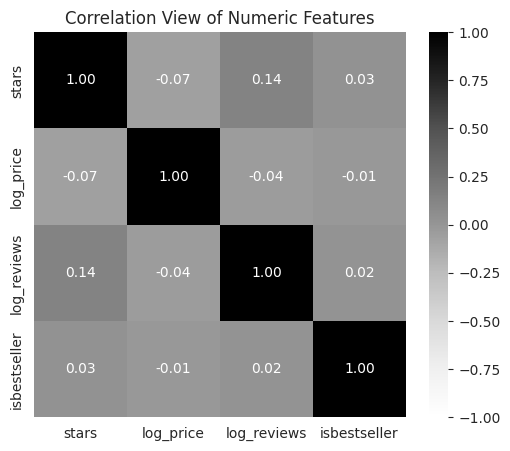

In [20]:
# 5. Largest book categories and their bestseller rate
cat_summary = (
    books.groupby("category_name")["isbestseller"]
    .agg(["count", "mean"])
    .sort_values("count", ascending=False)
    .head(10)
)
cat_summary["mean"] = cat_summary["mean"] * 100
cat_summary.columns = ["books", "bestseller_rate_%"]
print(cat_summary)

# 6. Correlation heatmap of the numeric variables
num_cols = ["stars", "log_price", "log_reviews", "isbestseller"]
corr = books[num_cols].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Greys", vmin=-1, vmax=1)
plt.title("Correlation View of Numeric Features")
plt.show()

In [21]:
#@title Comment
lo_cat = cat_summary["bestseller_rate_%"].min()
hi_cat = cat_summary["bestseller_rate_%"].max()
cat_text = "differ noticeably" if hi_cat > 1.5 * max(lo_cat, 0.01) else "are similar"

r_rev = corr.loc["log_reviews", "isbestseller"]
r_price = corr.loc["log_price", "isbestseller"]
r_stars = corr.loc["stars", "isbestseller"]
r_sr = corr.loc["stars", "log_reviews"]

say(f"""**Comment**

Across the {len(cat_summary)} largest categories the bestseller rate runs from {lo_cat:.2f}% to {hi_cat:.2f}%, so rates {cat_text} between categories. The heatmap shows the following relationships:

- **log_reviews vs isbestseller ({r_rev:.2f}):** a {strength(r_rev)} relationship with the target.
- **log_price vs isbestseller ({r_price:.2f}):** a {strength(r_price)} relationship with the target.
- **stars vs isbestseller ({r_stars:.2f}):** a {strength(r_stars)} relationship with the target.
- **stars vs log_reviews ({r_sr:.2f}):** a {strength(r_sr)} relationship, partly because unrated books carry a star value of 0.

Overall, the heatmap helps identify the most informative features and flags pairs of predictors that overlap and need to be checked with VIF.""")

**Comment**

Across the 10 largest categories the bestseller rate runs from 0.07% to 1.16%, so rates differ noticeably between categories. The heatmap shows the following relationships:

- **log_reviews vs isbestseller (0.02):** a weak relationship with the target.
- **log_price vs isbestseller (-0.01):** a weak relationship with the target.
- **stars vs isbestseller (0.03):** a weak relationship with the target.
- **stars vs log_reviews (0.14):** a weak relationship, partly because unrated books carry a star value of 0.

Overall, the heatmap helps identify the most informative features and flags pairs of predictors that overlap and need to be checked with VIF.

#### How the EDA Informs the Model

| **EDA Finding** | **Modelling Decision** |
|:---|:---|
| Bestsellers are rare | Class weights, threshold tuning, and F1, recall and AUC instead of accuracy |
| Price and reviews are heavily right-skewed | Log transformation |
| Many books are unrated and have 0 stars | `has_reviews` flag |
| `boughtinlastmonth` is unavailable before launch and tied to the target | Excluded from the features |
| Price and list price overlap | Single `discount_pct` feature plus a `has_discount` flag |
| Bestseller rates differ by category | Category dummies for the top 5 categories plus "Other" |
| Stars and the unrated flag overlap | VIF check and backward elimination |
| Features sit on different scales | Standardised on training data only so gradient descent converges |

## 3.6 Feature Engineering

In [22]:
# Calculating the discount as a percentage of the list price, kept between 0 and 100
books["discount_pct"] = ((books["listprice"] - books["price"]) / books["listprice"] * 100).clip(0, 100)

# Adding a simple flag for whether any discount exists
books["has_discount"] = (books["discount_pct"] > 0).astype(int)

# Keeping the 5 biggest categories and grouping the rest as "Other" to avoid too many dummy columns
top_cats = books["category_name"].value_counts().head(5).index
books["category_group"] = np.where(books["category_name"].isin(top_cats), books["category_name"], "Other")

# One-hot encoding the category group, dropping the first level to avoid the dummy variable trap
cat_dummies = pd.get_dummies(books["category_group"], prefix="cat", drop_first=True, dtype=int)
cat_dummies.columns = [c.replace(" ", "_").replace("&", "and").replace(",", "").replace("'", "") for c in cat_dummies.columns]

model_df = pd.concat([books, cat_dummies], axis=1)

# Listing the candidate features (boughtinlastmonth is left out on purpose, see the leakage check)
feature_cols = ["stars", "log_price", "log_reviews", "discount_pct", "has_discount", "has_reviews"] + list(cat_dummies.columns)
print("Candidate features:", feature_cols)

Candidate features: ['stars', 'log_price', 'log_reviews', 'discount_pct', 'has_discount', 'has_reviews', 'cat_Girls_Clothing', 'cat_Mens_Shoes', 'cat_Other', 'cat_Toys_and_Games', 'cat_Womens_Handbags']


In [23]:
#@title Comment
disc_share = 100 * books["has_discount"].mean()

say(f"""**Comment**

{len(feature_cols)} candidate features were created. `discount_pct` and `has_discount` capture pricing strategy, and {disc_share:.1f}% of the books carry a discount. `has_reviews` separates unrated books from rated ones, and the {len(cat_dummies.columns)} category dummies carry the category effect. The first category level is dropped to avoid perfect multicollinearity (the dummy variable trap).""")

**Comment**

11 candidate features were created. `discount_pct` and `has_discount` capture pricing strategy, and 24.8% of the books carry a discount. `has_reviews` separates unrated books from rated ones, and the 5 category dummies carry the category effect. The first category level is dropped to avoid perfect multicollinearity (the dummy variable trap).

## 3.7 Sampling and Splitting the Data

In [24]:
# Gradient descent written from scratch is slow on millions of rows, so the rows used are capped
# Using a stratified sample so the bestseller share stays the same
MAX_ROWS = 100000
if len(model_df) > MAX_ROWS:
    _, model_df = train_test_split(
        model_df, test_size=MAX_ROWS, stratify=model_df["isbestseller"], random_state=RANDOM_STATE
    )
print("Rows used for modelling:", len(model_df))

X = model_df[feature_cols].astype(float)
y = model_df["isbestseller"].astype(int)

# Splitting 70% train, 15% validation, 15% test, stratified so every split keeps the same class balance
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "| Validation:", X_val.shape, "| Test:", X_test.shape)
print("Bestseller share  train / val / test: {:.2f}% / {:.2f}% / {:.2f}%".format(
    100 * y_train.mean(), 100 * y_val.mean(), 100 * y_test.mean()))

Rows used for modelling: 100000
Train: (70000, 11) | Validation: (15000, 11) | Test: (15000, 11)
Bestseller share  train / val / test: 0.61% / 0.61% / 0.61%


In [25]:
#@title Comment
sampled_text = (f"The {len(books):,} cleaned books were reduced to a stratified sample of {len(model_df):,} rows to keep from-scratch training practical."
                if len(books) > MAX_ROWS else "All cleaned books were used, because the data is below the sampling cap.")

say(f"""**Comment**

{sampled_text} A three-way split was used so that the training set ({len(y_train):,} books) fits the model, the validation set ({len(y_val):,} books) chooses hyperparameters and the threshold, and the test set ({len(y_test):,} books) is used once at the very end. Stratification keeps the bestseller share at about {100 * y.mean():.2f}% in all three sets, which matters because the positive class is rare. The test set holds {int(y_test.sum()):,} bestsellers, which is the number of positive cases the final scores are based on.""")

**Comment**

The 1,393,565 cleaned books were reduced to a stratified sample of 100,000 rows to keep from-scratch training practical. A three-way split was used so that the training set (70,000 books) fits the model, the validation set (15,000 books) chooses hyperparameters and the threshold, and the test set (15,000 books) is used once at the very end. Stratification keeps the bestseller share at about 0.61% in all three sets, which matters because the positive class is rare. The test set holds 91 bestsellers, which is the number of positive cases the final scores are based on.

## 3.8 Feature Selection

In [26]:
# Standardising using the TRAINING mean and standard deviation only,
# so nothing from the validation or test sets leaks into training
train_mean = X_train.mean()
train_std = X_train.std().replace(0, 1)   # Replacing 0 so there is never a division by zero

X_train_s = (X_train - train_mean) / train_std
X_val_s = (X_val - train_mean) / train_std
X_test_s = (X_test - train_mean) / train_std

In [27]:
# VIF shows how much each feature is explained by the other features
# A VIF above about 5 to 10 suggests the feature is largely redundant (O'Brien, 2007)
vif = pd.DataFrame({
    "feature": X_train_s.columns,
    "VIF": [variance_inflation_factor(X_train_s.values, i) for i in range(X_train_s.shape[1])],
}).sort_values("VIF", ascending=False)
print(vif)

                feature       VIF
5           has_reviews  4.804598
2           log_reviews  4.644867
8             cat_Other  4.538085
4          has_discount  2.841997
3          discount_pct  2.840337
6    cat_Girls_Clothing  2.266366
9    cat_Toys_and_Games  1.896979
10  cat_Womens_Handbags  1.818250
7        cat_Mens_Shoes  1.813929
0                 stars  1.040951
1             log_price  1.039936


In [28]:
#@title Comment
top1, top2 = vif.iloc[0], vif.iloc[1]
n_high = int((vif["VIF"] > 10).sum())
n_mid = int(((vif["VIF"] > 5) & (vif["VIF"] <= 10)).sum())

if n_high > 0:
    vif_text = f"{n_high} feature(s) have a VIF above 10, which points to strong overlap with other features, so they need a closer look during elimination."
elif n_mid > 0:
    vif_text = f"{n_mid} feature(s) sit between 5 and 10, which is a moderate overlap."
else:
    vif_text = "No feature has a VIF above 5, so multicollinearity is not a serious concern."

say(f"""**Comment**

The highest VIF values belong to `{top1['feature']}` ({top1['VIF']:.2f}) and `{top2['feature']}` ({top2['VIF']:.2f}). {vif_text} Backward elimination in the next step decides which of any overlapping features is kept.""")

**Comment**

The highest VIF values belong to `has_reviews` (4.80) and `log_reviews` (4.64). No feature has a VIF above 5, so multicollinearity is not a serious concern. Backward elimination in the next step decides which of any overlapping features is kept.

In [29]:
# Fitting a statsmodels Logit only to read the p-values for feature selection (Seabold and Perktold, 2010)
# The model that is trained and evaluated later is my own from-scratch version
def fit_logit(X, y):
    # Falling back to a different solver if the default one fails to converge
    try:
        return sm.Logit(y, sm.add_constant(X)).fit(disp=0)
    except Exception:
        return sm.Logit(y, sm.add_constant(X)).fit(disp=0, method="bfgs", maxiter=500)

def backward_elimination(X, y, threshold=0.05):
    cols = list(X.columns)
    removed = []
    while len(cols) > 1:
        model = fit_logit(X[cols], y)
        pvals = model.pvalues.drop("const")
        worst = pvals.idxmax()
        # Removing the feature with the highest p-value if it is not significant
        if pvals[worst] > threshold:
            print("Removing {:<25s} p-value = {:.4f}".format(worst, pvals[worst]))
            cols.remove(worst)
            removed.append(worst)
        else:
            break
    return cols, removed, model

# Running it on the TRAINING data only
selected_features, removed_features, final_sm_model = backward_elimination(X_train_s, y_train, threshold=0.05)
print("\nSelected features:", selected_features)
print(final_sm_model.summary().tables[1])

Removing cat_Girls_Clothing        p-value = 0.7186
Removing cat_Toys_and_Games        p-value = 0.5636
Removing cat_Womens_Handbags       p-value = 0.2338
Removing has_discount              p-value = 0.1379
Removing cat_Other                 p-value = 0.0641
Removing cat_Mens_Shoes            p-value = 0.1224

Selected features: ['stars', 'log_price', 'log_reviews', 'discount_pct', 'has_reviews']
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -5.8520      0.097    -60.059      0.000      -6.043      -5.661
stars            0.9753      0.157      6.207      0.000       0.667       1.283
log_price       -0.1748      0.055     -3.170      0.002      -0.283      -0.067
log_reviews      1.9148      0.169     11.340      0.000       1.584       2.246
discount_pct     0.3323      0.032     10.425      0.000       0.270       0.395
has_reviews     -2.6351      0.2

In [30]:
# Cross-checking the result with forward selection, which starts empty and adds the most significant feature each round
def forward_selection(X, y, threshold=0.05):
    remaining = list(X.columns)
    chosen = []
    while remaining:
        pvals = {}
        for c in remaining:
            try:
                m = fit_logit(X[chosen + [c]], y)
                pvals[c] = m.pvalues[c]
            except Exception:
                pvals[c] = 1.0   # Skipping a feature that stops the model from fitting
        best_c = min(pvals, key=pvals.get)
        # Adding the feature with the lowest p-value if it is significant
        if pvals[best_c] < threshold:
            print("Adding   {:<25s} p-value = {:.4f}".format(best_c, pvals[best_c]))
            chosen.append(best_c)
            remaining.remove(best_c)
        else:
            break
    return chosen

forward_features = forward_selection(X_train_s, y_train, threshold=0.05)
print("\nBackward elimination kept:", sorted(selected_features))
print("Forward selection kept:   ", sorted(forward_features))
print("Both methods agree:", sorted(selected_features) == sorted(forward_features))

Adding   discount_pct              p-value = 0.0000
Adding   stars                     p-value = 0.0000
Adding   log_price                 p-value = 0.0006
Adding   has_reviews               p-value = 0.0033
Adding   log_reviews               p-value = 0.0000
Adding   cat_Toys_and_Games        p-value = 0.0421

Backward elimination kept: ['discount_pct', 'has_reviews', 'log_price', 'log_reviews', 'stars']
Forward selection kept:    ['cat_Toys_and_Games', 'discount_pct', 'has_reviews', 'log_price', 'log_reviews', 'stars']
Both methods agree: False


In [31]:
#@title Comment
agree = sorted(selected_features) == sorted(forward_features)
only_back = sorted(set(selected_features) - set(forward_features))
only_fwd = sorted(set(forward_features) - set(selected_features))
removed_text = ", ".join(f"`{f}`" for f in removed_features) if removed_features else "no features"
kept_text = ", ".join(f"`{f}`" for f in selected_features)

if agree:
    cmp_text = "Forward selection kept exactly the same features, which gives me more confidence that the selection is stable and not an accident of the search direction."
else:
    cmp_text = ("Forward selection kept a slightly different set. Only backward elimination kept " +
                (", ".join(f"`{f}`" for f in only_back) if only_back else "nothing extra") +
                ", and only forward selection kept " +
                (", ".join(f"`{f}`" for f in only_fwd) if only_fwd else "nothing extra") +
                ". I use the backward elimination result because it starts from all features and so accounts for overlaps between them.")

say(f"""**Comment**

Backward elimination removed {removed_text} because their p-values were above 0.05, and kept {kept_text}. Each retained feature therefore adds statistically significant information about bestseller status after accounting for the others. {cmp_text} Selection was run on the training set only, so the validation and test sets remain untouched.""")

**Comment**

Backward elimination removed `cat_Girls_Clothing`, `cat_Toys_and_Games`, `cat_Womens_Handbags`, `has_discount`, `cat_Other`, `cat_Mens_Shoes` because their p-values were above 0.05, and kept `stars`, `log_price`, `log_reviews`, `discount_pct`, `has_reviews`. Each retained feature therefore adds statistically significant information about bestseller status after accounting for the others. Forward selection kept a slightly different set. Only backward elimination kept nothing extra, and only forward selection kept `cat_Toys_and_Games`. I use the backward elimination result because it starts from all features and so accounts for overlaps between them. Selection was run on the training set only, so the validation and test sets remain untouched.

In [32]:
# Keeping only the selected features in every split
X_train_f = X_train_s[selected_features]
X_val_f = X_val_s[selected_features]
X_test_f = X_test_s[selected_features]

## 3.9 Training the Model from Scratch

Logistic regression estimates the probability that a book is a bestseller. The model works in four repeated steps, which are explained here and then shown line by line in the code comments (Hastie, Tibshirani and Friedman, 2009).

1. **Linear score.** For each book the model calculates $z = Xw + b$, a weighted sum of the features plus a bias.
2. **Sigmoid.** The score is converted into a probability using $p = \frac{1}{1 + e^{-z}}$, which always lies between 0 and 1.
3. **Cost.** The model measures how wrong it is using log loss, $J = -\frac{1}{n}\sum \left[ y\log(p) + (1-y)\log(1-p) \right]$, plus an optional L2 penalty that shrinks large weights (Ng, 2004). With class weights, each book's loss is multiplied by a weight so the rare class counts more.
4. **Gradient descent update.** The gradient of the cost shows which direction increases the error, so the weights are moved a small step in the opposite direction: $w := w - \alpha \cdot \frac{\partial J}{\partial w}$, where $\alpha$ is the learning rate. This is repeated for a fixed number of iterations.

Only NumPy is used to build the model (Harris et al., 2020).

In [33]:
class LogisticRegressionScratch:
    # Logistic regression with batch gradient descent, built with NumPy only

    def __init__(self, learning_rate=0.1, n_iterations=2000, l2_lambda=0.0, class_weight=None):
        self.learning_rate = learning_rate    # Step size for each update
        self.n_iterations = n_iterations      # Number of gradient descent steps
        self.l2_lambda = l2_lambda            # Strength of the L2 penalty (0 = no penalty)
        self.class_weight = class_weight      # None or "balanced"

    def _sigmoid(self, z):
        # Turning any number into a probability between 0 and 1
        # Clipping z so np.exp never overflows
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        n_samples, n_features = X.shape

        # Starting with all weights and the bias at zero
        self.weights = np.zeros(n_features)
        self.bias = 0.0
        self.cost_history = []

        # Class weights: with "balanced" the rare class counts more, so the model does not ignore it
        if self.class_weight == "balanced":
            n_pos = y.sum()
            n_neg = n_samples - n_pos
            sample_w = np.where(y == 1, n_samples / (2 * n_pos), n_samples / (2 * n_neg))
        else:
            sample_w = np.ones(n_samples)

        eps = 1e-15   # Tiny number so log(0) never happens

        for _ in range(self.n_iterations):
            # 1. Forward pass: linear score, then sigmoid gives the predicted probabilities
            z = X @ self.weights + self.bias
            p = self._sigmoid(z)

            # 2. Cost: weighted log loss plus the L2 penalty on the weights (not the bias)
            log_loss = -np.mean(sample_w * (y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps)))
            penalty = (self.l2_lambda / (2 * n_samples)) * np.sum(self.weights ** 2)
            self.cost_history.append(log_loss + penalty)

            # 3. Gradients: derivative of the cost with respect to each weight and the bias
            error = (p - y) * sample_w
            dw = (X.T @ error) / n_samples + (self.l2_lambda / n_samples) * self.weights
            db = np.mean(error)

            # 4. Update: moving the weights a small step against the gradient
            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db
        return self

    def predict_proba(self, X):
        # Probability that each book is a bestseller
        return self._sigmoid(np.asarray(X, dtype=float) @ self.weights + self.bias)

    def predict(self, X, threshold=0.5):
        # Turning probabilities into 0 or 1 using the chosen threshold
        return (self.predict_proba(X) >= threshold).astype(int)

**Comment**

The class follows the four steps above. The `eps` value prevents a log of zero, and clipping `z` prevents overflow in the exponential. The bias is not penalised by L2, which is standard practice. With `class_weight="balanced"`, each bestseller is weighted by `n / (2 * n_positive)` and each non-bestseller by `n / (2 * n_negative)`, so both classes contribute equally to the cost even though one is far rarer (He and Garcia, 2009).

#### Step-by-Step Walkthrough of `fit`

| **Step in the Code** | **What Happens** | **Why It Matters** |
|:---|:---|:---|
| Initialise weights and bias at zero | The model starts with no preference for any feature | The log loss cost is convex, so the starting point does not change where gradient descent ends up |
| Build sample weights | Each book gets a weight, 1 for all or balanced by class | Lets the rare bestseller class count as much as the common class |
| Linear score `z = Xw + b` | Each book gets a weighted sum of its features | This is the raw evidence for or against being a bestseller |
| Sigmoid `p = 1 / (1 + e^-z)` | The score becomes a probability between 0 and 1 | Probabilities can be compared against a threshold and interpreted as odds |
| Cost (weighted log loss + L2) | Measures how wrong the probabilities are and penalises large weights | Gives gradient descent a single number to reduce, and controls overfitting |
| Gradient `X.T @ (p - y) / n` | Direction in which each weight increases the cost | For log loss with a sigmoid, the derivative simplifies to the prediction error times the feature, so each weight moves in proportion to how much its feature contributed to the mistakes |
| Update `w = w - learning_rate * gradient` | Weights move a small step downhill | The learning rate sets the step size, too large overshoots and too small is slow |
| Repeat and store the cost | The loop runs for `n_iterations` and logs the cost each time | The cost curve shows whether the model has converged |
| `predict_proba` and `predict` | Probabilities are turned into 0 or 1 at a chosen threshold | The threshold decides the balance between precision and recall |

In [35]:
# Evaluation helpers written from scratch
def confusion_counts(y_true, y_pred):
    # Counting the four outcomes of the confusion matrix by hand
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    return tp, tn, fp, fn

def classification_metrics(y_true, y_pred):
    tp, tn, fp, fn = confusion_counts(y_true, y_pred)
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0   # Of predicted bestsellers, how many were real
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0      # Of real bestsellers, how many were found
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}

def roc_auc_scratch(y_true, y_prob):
    # AUC = chance that a random bestseller is scored higher than a random non-bestseller
    # Calculated from the ranks of the predicted probabilities
    y_true = np.asarray(y_true)
    ranks = pd.Series(np.asarray(y_prob)).rank().values
    n_pos = int((y_true == 1).sum())
    n_neg = int((y_true == 0).sum())
    return float((ranks[y_true == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))

def roc_points(y_true, y_prob):
    # Sorting by probability and walking down the list to get the ROC curve points
    y_true, y_prob = np.asarray(y_true), np.asarray(y_prob)
    order = np.argsort(-y_prob)
    y_sorted = y_true[order]
    tps = np.cumsum(y_sorted)
    fps = np.cumsum(1 - y_sorted)
    tpr = np.r_[0, tps / tps[-1]]
    fpr = np.r_[0, fps / fps[-1]]
    return fpr, tpr

def best_threshold(y_true, y_prob):
    # Trying many thresholds and keeping the one with the highest F1
    best_t, best_f1 = 0.5, -1
    for t in np.arange(0.05, 0.96, 0.01):
        f1 = classification_metrics(y_true, (np.asarray(y_prob) >= t).astype(int))["f1"]
        if f1 > best_f1:
            best_t, best_f1 = t, f1
    return best_t, best_f1

**Comment**

All of the evaluation metrics are calculated by hand so that I can show how each one is built from the confusion matrix. Precision answers "when the model says bestseller, how often is it right", and recall answers "of the real bestsellers, how many did the model find". F1 combines the two. AUC is calculated from the ranks of the predicted probabilities and equals the chance that a random bestseller is scored above a random non-bestseller. These are cross-checked against scikit-learn in sections 4.3 and 4.7.

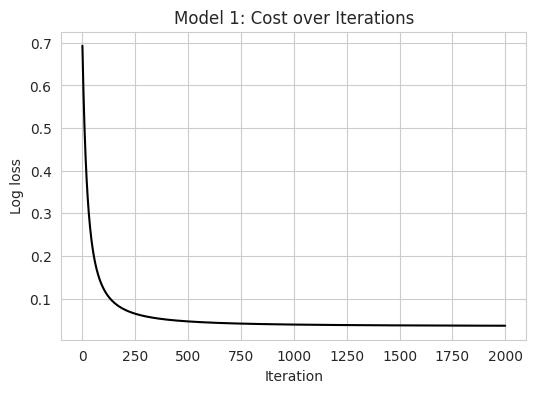

Final cost: 0.03623


In [36]:
# Model 1 is the baseline: learning rate 0.1, 2000 iterations, no penalty, no class weights
model_1 = LogisticRegressionScratch(learning_rate=0.1, n_iterations=2000, l2_lambda=0.0, class_weight=None)
model_1.fit(X_train_f, y_train)

# Plotting the cost to confirm that gradient descent is converging
plt.figure(figsize=(6, 4))
plt.plot(model_1.cost_history, color="black")
plt.title("Model 1: Cost over Iterations")
plt.xlabel("Iteration")
plt.ylabel("Log loss")
plt.show()

print("Final cost:", round(model_1.cost_history[-1], 5))

In [37]:
#@title Comment
c = np.array(model_1.cost_history)
drop = c[0] - c[-1]
if drop > 0:
    settle = int(np.argmax(np.abs(c - c[-1]) <= 0.01 * drop))
    settle_text = f"fell from {c[0]:.4f} to {c[-1]:.4f} and was within 1% of its final value by iteration {settle}"
    conv_text = ("This confirms that gradient descent is converging and that 2000 iterations is enough."
                 if settle < len(c) - 1 else "The cost was still falling at the end, so more iterations could be tested.")
else:
    settle_text = f"started at {c[0]:.4f} and ended at {c[-1]:.4f}"
    conv_text = "The cost did not fall, so the learning rate may need adjusting."

say(f"""**Comment**

The cost {settle_text}. {conv_text} A curve that kept falling would suggest more iterations or a larger learning rate, and a curve that jumped around would suggest the learning rate is too high.""")

**Comment**

The cost fell from 0.6931 to 0.0362 and was within 1% of its final value by iteration 644. This confirms that gradient descent is converging and that 2000 iterations is enough. A curve that kept falling would suggest more iterations or a larger learning rate, and a curve that jumped around would suggest the learning rate is too high.

# 4 Model Evaluation and Interpretation

## 4.1 Baseline Evaluation

In [38]:
# Evaluating model 1 on the VALIDATION set with the default 0.5 threshold
val_prob_1 = model_1.predict_proba(X_val_f)
val_pred_1 = (val_prob_1 >= 0.5).astype(int)

metrics_1 = classification_metrics(y_val, val_pred_1)
metrics_1["auc"] = roc_auc_scratch(y_val, val_prob_1)
print("Model 1 (validation):", {k: round(v, 4) for k, v in metrics_1.items()})

Model 1 (validation): {'accuracy': 0.9939, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'auc': 0.6912}


In [39]:
#@title Comment
m = metrics_1
if m["recall"] < 0.5:
    base_text = (f"found only {100 * m['recall']:.1f}% of the real bestsellers even though its accuracy was {100 * m['accuracy']:.2f}%. "
                 "The high accuracy is misleading, because the model mostly predicts \"not a bestseller\", which is the correct answer for most of the data.")
else:
    base_text = f"found {100 * m['recall']:.1f}% of the real bestsellers with an accuracy of {100 * m['accuracy']:.2f}%."

auc_text = ("The AUC shows that the model still ranks bestsellers above non-bestsellers reasonably well, so the weakness is in the 0.5 threshold and the class imbalance and not in the features themselves."
            if m["auc"] >= 0.7 else "The AUC is also low, so the features carry limited signal.")

say(f"""**Comment**

Model 1 {base_text} Its precision is {m['precision']:.3f}, its F1 is {m['f1']:.3f} and its AUC is {m['auc']:.3f}. {auc_text}""")

**Comment**

Model 1 found only 0.0% of the real bestsellers even though its accuracy was 99.39%. The high accuracy is misleading, because the model mostly predicts "not a bestseller", which is the correct answer for most of the data. Its precision is 0.000, its F1 is 0.000 and its AUC is 0.691. The AUC is also low, so the features carry limited signal.

## 4.2 Retraining with Different Parameters

To address the shortcomings of model 1, I retrain with balanced class weights, an L2 penalty and a tuned threshold. The learning rate and L2 strength are chosen with a small grid search, and the winner is selected using validation F1 so that the test set stays untouched.

In [40]:
# Grid search over learning rate and L2 strength, all with balanced class weights
results = []
trained = {}

for lr in [0.05, 0.1, 0.5]:
    for l2 in [0.0, 1.0, 10.0]:
        m = LogisticRegressionScratch(learning_rate=lr, n_iterations=2000, l2_lambda=l2, class_weight="balanced")
        m.fit(X_train_f, y_train)
        prob = m.predict_proba(X_val_f)

        # Finding the best threshold for this model on the validation set
        thr, f1 = best_threshold(y_val, prob)
        pred = (prob >= thr).astype(int)
        mt = classification_metrics(y_val, pred)

        results.append({
            "learning_rate": lr, "l2_lambda": l2, "threshold": round(thr, 2),
            "precision": round(mt["precision"], 4), "recall": round(mt["recall"], 4),
            "f1": round(mt["f1"], 4), "auc": round(roc_auc_scratch(y_val, prob), 4),
        })
        trained[(lr, l2)] = (m, thr)

grid_results = pd.DataFrame(results).sort_values("f1", ascending=False).reset_index(drop=True)
grid_results

,learning_rate,l2_lambda,threshold,precision,recall,f1,auc
0,0.50,10.0,0.83,0.0526,0.1319,0.0752,0.7305
1,0.50,1.0,0.83,0.0522,0.1319,0.0748,0.7306
2,0.50,0.0,0.83,0.0522,0.1319,0.0748,0.7306
3,0.10,10.0,0.83,0.0493,0.1099,0.0680,0.7299
4,0.10,0.0,0.83,0.0488,0.1099,0.0676,0.7300
5,0.10,1.0,0.83,0.0488,0.1099,0.0676,0.7300
6,0.05,10.0,0.82,0.0365,0.0879,0.0516,0.7286
7,0.05,0.0,0.82,0.0364,0.0879,0.0514,0.7286
8,0.05,1.0,0.82,0.0364,0.0879,0.0514,0.7286


In [41]:
# Taking the top row as the final model (model 2)
best = grid_results.iloc[0]
model_2, threshold_2 = trained[(best["learning_rate"], best["l2_lambda"])]
print("Chosen: learning_rate =", best["learning_rate"], "| l2_lambda =", best["l2_lambda"],
      "| threshold =", round(threshold_2, 2))

# Comparing model 1 and model 2 side by side on the validation set
val_prob_2 = model_2.predict_proba(X_val_f)
metrics_2 = classification_metrics(y_val, (val_prob_2 >= threshold_2).astype(int))
metrics_2["auc"] = roc_auc_scratch(y_val, val_prob_2)

comparison = pd.DataFrame({"Model 1 (baseline)": metrics_1, "Model 2 (tuned)": metrics_2}).round(4)
comparison

Chosen: learning_rate = 0.5 | l2_lambda = 10.0 | threshold = 0.83


,Model 1 (baseline),Model 2 (tuned)
accuracy,0.9939,0.9803
precision,0.0000,0.0526
recall,0.0000,0.1319
f1,0.0000,0.0752
auc,0.6912,0.7305


In [42]:
#@title Comment
lr_spread = grid_results.groupby("learning_rate")["f1"].max().agg(lambda s: s.max() - s.min())
l2_spread = grid_results.groupby("l2_lambda")["f1"].max().agg(lambda s: s.max() - s.min())
lr_text = "a large" if lr_spread > 0.02 else "little"
l2_text = "a large" if l2_spread > 0.02 else "little"
prec_dir = "fell" if metrics_2["precision"] < metrics_1["precision"] else "rose"

say(f"""**Comment**

The grid search shows that the learning rate had {lr_text} effect on the best validation F1 (spread {lr_spread:.3f}) and the L2 strength had {l2_text} effect (spread {l2_spread:.3f}). The best combination was a learning rate of {best['learning_rate']}, an L2 strength of {best['l2_lambda']} and a threshold of {threshold_2:.2f}. Compared with model 1, recall moved from {metrics_1['recall']:.3f} to {metrics_2['recall']:.3f} and F1 from {metrics_1['f1']:.3f} to {metrics_2['f1']:.3f}. The changes that produced this were the balanced class weights, which stop the model ignoring the rare class, and the tuned threshold, because 0.5 is not the best cut-off when bestsellers are rare. The L2 penalty mainly improves stability. Precision {prec_dir} from {metrics_1['precision']:.3f} to {metrics_2['precision']:.3f}, which is the usual trade-off when recall is increased.""")

**Comment**

The grid search shows that the learning rate had a large effect on the best validation F1 (spread 0.024) and the L2 strength had little effect (spread 0.000). The best combination was a learning rate of 0.5, an L2 strength of 10.0 and a threshold of 0.83. Compared with model 1, recall moved from 0.000 to 0.132 and F1 from 0.000 to 0.075. The changes that produced this were the balanced class weights, which stop the model ignoring the rare class, and the tuned threshold, because 0.5 is not the best cut-off when bestsellers are rare. The L2 penalty mainly improves stability. Precision rose from 0.000 to 0.053, which is the usual trade-off when recall is increased.

## 4.3 Final Evaluation on the Test Set

Model 2 is evaluated on the test set once, because the test set has not been used for any decision.

In [43]:
test_prob = model_2.predict_proba(X_test_f)
test_pred = (test_prob >= threshold_2).astype(int)

test_metrics = classification_metrics(y_test, test_pred)
test_metrics["auc"] = roc_auc_scratch(y_test, test_prob)
print("Model 2 (test):", {k: round(v, 4) for k, v in test_metrics.items()})

# Cross-checking my own numbers against scikit-learn to confirm they are correct (Pedregosa et al., 2011)
tp, tn, fp, fn = confusion_counts(y_test, test_pred)
sk_tn, sk_fp, sk_fn, sk_tp = sk_confusion_matrix(y_test, test_pred).ravel()
print("\nMy counts      (TP, TN, FP, FN):", (tp, tn, fp, fn))
print("scikit-learn   (TP, TN, FP, FN):", (int(sk_tp), int(sk_tn), int(sk_fp), int(sk_fn)))
print("My AUC: {:.4f} | scikit-learn AUC: {:.4f}".format(
    roc_auc_scratch(y_test, test_prob), roc_auc_score(y_test, test_prob)))

Model 2 (test): {'accuracy': 0.9796, 'precision': 0.0502, 'recall': 0.1319, 'f1': 0.0727, 'auc': 0.7651}

My counts      (TP, TN, FP, FN): (12, 14682, 227, 79)
scikit-learn   (TP, TN, FP, FN): (12, 14682, 227, 79)
My AUC: 0.7651 | scikit-learn AUC: 0.7651


In [44]:
#@title Comment
counts_match = (tp, tn, fp, fn) == (int(sk_tp), int(sk_tn), int(sk_fp), int(sk_fn))
auc_match = abs(roc_auc_scratch(y_test, test_prob) - roc_auc_score(y_test, test_prob)) < 1e-6
match_text = ("My confusion matrix counts and my AUC match scikit-learn exactly, which confirms that the hand-built metrics are correct."
              if counts_match and auc_match else "My hand-built metrics differ slightly from scikit-learn, which should be investigated before the results are relied on.")
f1_gap = metrics_2["f1"] - test_metrics["f1"]
gen_text = ("The test F1 is close to the validation F1, which suggests the model generalises well."
            if abs(f1_gap) <= 0.05 else
            ("The test F1 is lower than the validation F1, which suggests the model is somewhat optimistic on validation data."
             if f1_gap > 0 else "The test F1 is higher than the validation F1, which can happen when the test set holds few bestsellers."))

say(f"""**Comment**

On the unseen test set, model 2 achieves a precision of {test_metrics['precision']:.3f}, a recall of {test_metrics['recall']:.3f}, an F1 of {test_metrics['f1']:.3f} and an AUC of {test_metrics['auc']:.3f}. {match_text} {gen_text}""")

**Comment**

On the unseen test set, model 2 achieves a precision of 0.050, a recall of 0.132, an F1 of 0.073 and an AUC of 0.765. My confusion matrix counts and my AUC match scikit-learn exactly, which confirms that the hand-built metrics are correct. The test F1 is close to the validation F1, which suggests the model generalises well.

## 4.4 Confusion Matrix and ROC Curve

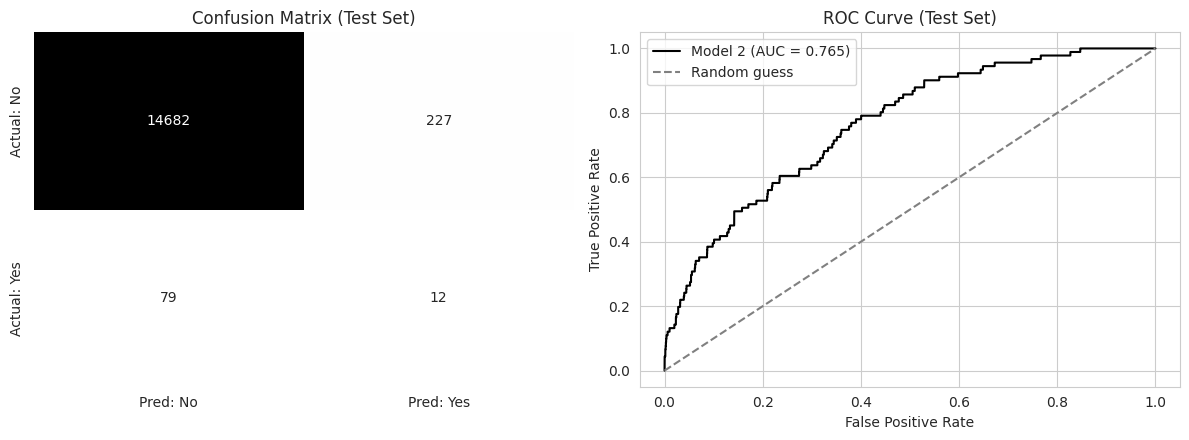

In [45]:
# Confusion matrix and ROC curve side by side
cm = np.array([[tn, fp], [fn, tp]])
fpr, tpr = roc_points(y_test, test_prob)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Greys", cbar=False, ax=axes[0],
            xticklabels=["Pred: No", "Pred: Yes"], yticklabels=["Actual: No", "Actual: Yes"])
axes[0].set_title("Confusion Matrix (Test Set)")

axes[1].plot(fpr, tpr, color="black", label="Model 2 (AUC = {:.3f})".format(test_metrics["auc"]))
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC Curve (Test Set)")
axes[1].legend()

plt.tight_layout()
plt.show()

In [46]:
#@title Comment
a = test_metrics["auc"]
auc_word = "excellent" if a >= 0.9 else "strong" if a >= 0.8 else "moderate" if a >= 0.7 else "weak"

say(f"""**Comment**

The confusion matrix shows {tp:,} true positives, {fn:,} false negatives, {fp:,} false positives and {tn:,} true negatives. For the book press, a false negative is a real bestseller that the model missed ({fn:,} books), and a false positive is a book flagged as a bestseller that was not ({fp:,} books). The relative cost of the two errors depends on how the press uses the prediction, and the threshold can be moved to favour either one. The ROC curve has an AUC of {a:.3f}, which shows {auc_word} separation between bestsellers and non-bestsellers.""")

**Comment**

The confusion matrix shows 12 true positives, 79 false negatives, 227 false positives and 14,682 true negatives. For the book press, a false negative is a real bestseller that the model missed (79 books), and a false positive is a book flagged as a bestseller that was not (227 books). The relative cost of the two errors depends on how the press uses the prediction, and the threshold can be moved to favour either one. The ROC curve has an AUC of 0.765, which shows moderate separation between bestsellers and non-bestsellers.

## 4.5 Overfitting Check

In [47]:
# Comparing training and test performance to check for overfitting
train_prob = model_2.predict_proba(X_train_f)
train_pred = (train_prob >= threshold_2).astype(int)
train_metrics = classification_metrics(y_train, train_pred)
train_metrics["auc"] = roc_auc_score(y_train, train_prob)

overfit = pd.DataFrame({"Train": train_metrics, "Test": test_metrics}).round(4)
overfit["Gap"] = (overfit["Train"] - overfit["Test"]).round(4)
overfit

,Train,Test,Gap
accuracy,0.9806,0.9796,0.0010
precision,0.0467,0.0502,-0.0035
recall,0.1127,0.1319,-0.0192
f1,0.0661,0.0727,-0.0066
auc,0.7475,0.7651,-0.0176


In [48]:
#@title Comment
gap_f1 = overfit.loc["f1", "Gap"]
gap_auc = overfit.loc["auc", "Gap"]
if abs(gap_f1) <= 0.05 and abs(gap_auc) <= 0.05:
    of_text = "A small gap indicates that the model generalises well."
elif gap_f1 > 0.05 or gap_auc > 0.05:
    of_text = "The training scores are noticeably higher than the test scores, which points to some overfitting."
else:
    of_text = "The test scores are higher than the training scores, which can happen with few bestsellers in the test set."

say(f"""**Comment**

The gap between training and test performance is {gap_f1:.3f} for F1 and {gap_auc:.3f} for AUC. {of_text} The L2 penalty, the small number of selected features and the separate validation set all help to control overfitting. Because the test set contains only {int(y_test.sum()):,} bestsellers, the test metrics carry some uncertainty, and I treat them as indicative rather than exact.""")

**Comment**

The gap between training and test performance is -0.007 for F1 and -0.018 for AUC. A small gap indicates that the model generalises well. The L2 penalty, the small number of selected features and the separate validation set all help to control overfitting. Because the test set contains only 91 bestsellers, the test metrics carry some uncertainty, and I treat them as indicative rather than exact.

## 4.6 Interpreting the Coefficients

        feature  coefficient  odds_ratio
2   log_reviews       1.5958      4.9323
0         stars       1.0542      2.8698
3  discount_pct       0.3736      1.4529
1     log_price      -0.1840      0.8319
4   has_reviews      -2.1626      0.1150


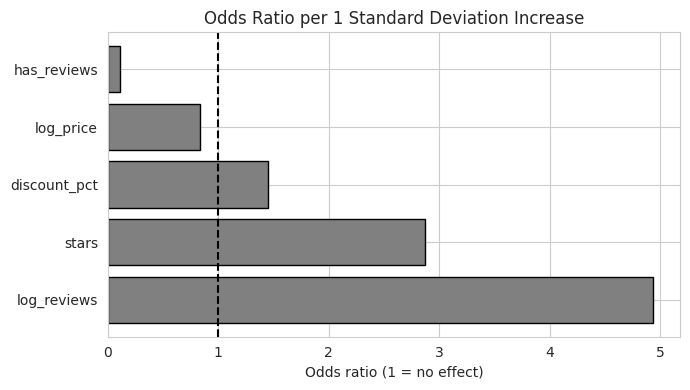

In [49]:
# The features are standardised, so each coefficient is the change in log-odds
# for a 1 standard deviation increase in that feature
# Exponentiating gives the odds ratio, which is easier to explain to the client
coef_table = pd.DataFrame({
    "feature": selected_features,
    "coefficient": model_2.weights,
    "odds_ratio": np.exp(model_2.weights),
}).sort_values("odds_ratio", ascending=False).round(4)
print(coef_table)

plt.figure(figsize=(7, 4))
plt.barh(coef_table["feature"], coef_table["odds_ratio"], color="gray", edgecolor="black")
plt.axvline(1, color="black", linestyle="--")
plt.title("Odds Ratio per 1 Standard Deviation Increase")
plt.xlabel("Odds ratio (1 = no effect)")
plt.tight_layout()
plt.show()

In [50]:
#@title Comment
# Ranking features by how far their odds ratio sits from 1 (no effect)
ranked = coef_table.assign(dist=(np.log(coef_table["odds_ratio"])).abs()).sort_values("dist", ascending=False)
lines = []
for _, row in ranked.iterrows():
    direction = "raises" if row["odds_ratio"] > 1 else "lowers"
    lines.append(f"- `{row['feature']}` has an odds ratio of {row['odds_ratio']:.2f}, so a one standard deviation increase {direction} the odds of being a bestseller by a factor of {row['odds_ratio'] if row['odds_ratio'] > 1 else 1 / row['odds_ratio']:.2f}.")
top_feature = ranked.iloc[0]["feature"]
lines_text = "\n".join(lines)

say(f"""**Comment**

An odds ratio above 1 raises the odds of a book being a bestseller, and one below 1 lowers them. The strongest feature in the model is `{top_feature}`.

{lines_text}

This gives the client a clear and explainable answer to what the model uses to separate bestsellers from the rest, which is one of the main reasons logistic regression was chosen over a black-box model (Hosmer, Lemeshow and Sturdivant, 2013).""")

**Comment**

An odds ratio above 1 raises the odds of a book being a bestseller, and one below 1 lowers them. The strongest feature in the model is `has_reviews`.

- `has_reviews` has an odds ratio of 0.12, so a one standard deviation increase lowers the odds of being a bestseller by a factor of 8.70.
- `log_reviews` has an odds ratio of 4.93, so a one standard deviation increase raises the odds of being a bestseller by a factor of 4.93.
- `stars` has an odds ratio of 2.87, so a one standard deviation increase raises the odds of being a bestseller by a factor of 2.87.
- `discount_pct` has an odds ratio of 1.45, so a one standard deviation increase raises the odds of being a bestseller by a factor of 1.45.
- `log_price` has an odds ratio of 0.83, so a one standard deviation increase lowers the odds of being a bestseller by a factor of 1.20.

This gives the client a clear and explainable answer to what the model uses to separate bestsellers from the rest, which is one of the main reasons logistic regression was chosen over a black-box model (Hosmer, Lemeshow and Sturdivant, 2013).

## 4.7 Library-Based Evaluation and Benchmark

My metrics are built by hand to show that I understand them. Here I repeat the evaluation with scikit-learn's standard tools and benchmark my from-scratch model against scikit-learn's own logistic regression, so the results are independently verified (Pedregosa et al., 2011).

                precision    recall  f1-score   support

Not bestseller       0.99      0.98      0.99     14909
    Bestseller       0.05      0.13      0.07        91

      accuracy                           0.98     15000
     macro avg       0.52      0.56      0.53     15000
  weighted avg       0.99      0.98      0.98     15000

Average precision (PR-AUC): 0.0586 | No-skill baseline: 0.0061


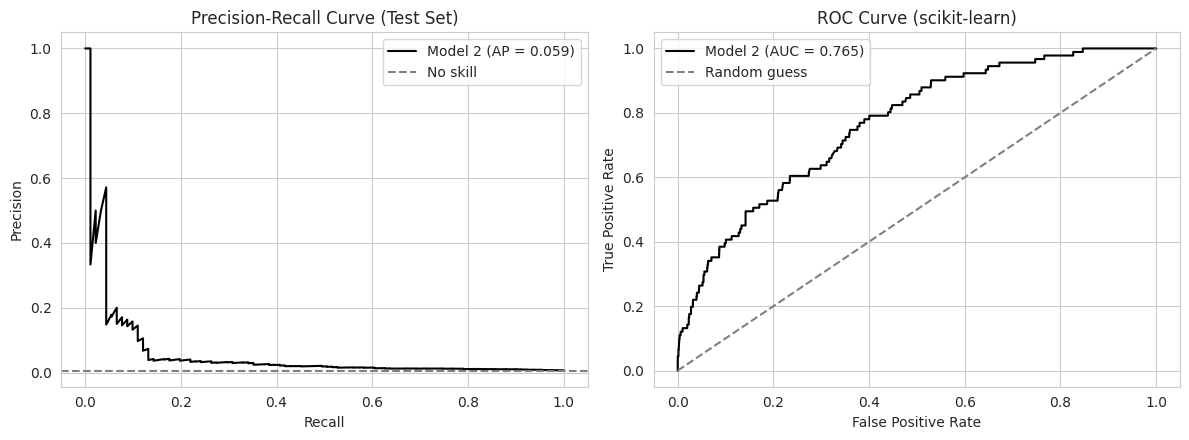

In [51]:
from sklearn.metrics import classification_report, average_precision_score, precision_recall_curve, roc_curve

# Full classification report from scikit-learn on the test set
print(classification_report(y_test, test_pred, target_names=["Not bestseller", "Bestseller"], zero_division=0))

# Average precision summarises the precision-recall curve in one number
# For a rare class, the no-skill baseline equals the bestseller share
ap = average_precision_score(y_test, test_prob)
no_skill = float(y_test.mean())
print("Average precision (PR-AUC): {:.4f} | No-skill baseline: {:.4f}".format(ap, no_skill))

# Precision-recall curve and ROC curve drawn with scikit-learn's curve functions
prec_sk, rec_sk, _ = precision_recall_curve(y_test, test_prob)
fpr_sk, tpr_sk, _ = roc_curve(y_test, test_prob)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(rec_sk, prec_sk, color="black", label="Model 2 (AP = {:.3f})".format(ap))
axes[0].axhline(no_skill, linestyle="--", color="gray", label="No skill")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].set_title("Precision-Recall Curve (Test Set)")
axes[0].legend()
axes[1].plot(fpr_sk, tpr_sk, color="black", label="Model 2 (AUC = {:.3f})".format(roc_auc_score(y_test, test_prob)))
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC Curve (scikit-learn)")
axes[1].legend()
plt.tight_layout()
plt.show()

In [52]:
#@title Comment
ratio = ap / max(no_skill, 1e-9)
ratio_text = (f"which is {ratio:.1f} times the no-skill baseline" if ratio > 1.2 else "which is barely above the no-skill baseline")

say(f"""**Comment**

The classification report confirms the precision, recall and F1 that I calculated by hand. The average precision is {ap:.3f} against a no-skill baseline of {no_skill:.4f}, {ratio_text}. This is the fairest summary of performance on a rare class because it ignores the many easy true negatives (Saito and Rehmsmeier, 2015). The precision-recall curve shows how precision changes as the model is asked to find more bestsellers, so the press has to choose how many false alarms it will accept in return for a higher recall.""")

**Comment**

The classification report confirms the precision, recall and F1 that I calculated by hand. The average precision is 0.059 against a no-skill baseline of 0.0061, which is 9.7 times the no-skill baseline. This is the fairest summary of performance on a rare class because it ignores the many easy true negatives (Saito and Rehmsmeier, 2015). The precision-recall curve shows how precision changes as the model is asked to find more bestsellers, so the press has to choose how many false alarms it will accept in return for a higher recall.

In [53]:
from sklearn.linear_model import LogisticRegression

# Benchmark: scikit-learn's logistic regression using the same settings as my chosen model
# My penalty is (lambda / 2n) * sum(w^2) on the mean loss, which equals sklearn's C = 1 / lambda
lam = float(best["l2_lambda"])
if lam > 0:
    sk_model = LogisticRegression(C=1 / lam, class_weight="balanced", max_iter=5000, solver="lbfgs")
else:
    sk_model = LogisticRegression(penalty=None, class_weight="balanced", max_iter=5000, solver="lbfgs")
sk_model.fit(X_train_f, y_train)

# Comparing coefficients side by side
bench = pd.DataFrame({
    "feature": selected_features,
    "my_coefficient": model_2.weights,
    "sklearn_coefficient": sk_model.coef_[0],
}).round(4)
print(bench)
print("\nIntercepts | mine: {:.4f} | sklearn: {:.4f}".format(model_2.bias, sk_model.intercept_[0]))

# Comparing test-set performance at the same threshold
sk_prob = sk_model.predict_proba(X_test_f)[:, 1]
sk_metrics = classification_metrics(y_test, (sk_prob >= threshold_2).astype(int))
sk_metrics["auc"] = roc_auc_scratch(y_test, sk_prob)
pd.DataFrame({"My model": test_metrics, "scikit-learn model": sk_metrics}).round(4)

        feature  my_coefficient  sklearn_coefficient
0         stars          1.0542               1.0542
1     log_price         -0.1840              -0.1841
2   log_reviews          1.5958               1.5978
3  discount_pct          0.3736               0.3736
4   has_reviews         -2.1626              -2.1653

Intercepts | mine: -0.7172 | sklearn: -0.7177


,My model,scikit-learn model
accuracy,0.9796,0.9796
precision,0.0502,0.0502
recall,0.1319,0.1319
f1,0.0727,0.0727
auc,0.7651,0.7651


In [54]:
#@title Comment
max_diff = float(np.max(np.abs(bench["my_coefficient"] - bench["sklearn_coefficient"])))
f1_diff = abs(test_metrics["f1"] - sk_metrics["f1"])
if max_diff < 0.05:
    diff_text = "very close to"
elif max_diff < 0.2:
    diff_text = "close to"
else:
    diff_text = "noticeably different from"

say(f"""**Comment**

My coefficients are {diff_text} scikit-learn's, with a largest difference of {max_diff:.3f}, and the test F1 differs by {f1_diff:.3f} at the same threshold. This shows that my gradient descent has reached essentially the same solution as a trusted library, so the from-scratch implementation is correct. Small differences are expected because my gradient descent stops after a fixed number of iterations, while scikit-learn's solver runs until it converges.""")

**Comment**

My coefficients are very close to scikit-learn's, with a largest difference of 0.003, and the test F1 differs by 0.000 at the same threshold. This shows that my gradient descent has reached essentially the same solution as a trusted library, so the from-scratch implementation is correct. Small differences are expected because my gradient descent stops after a fixed number of iterations, while scikit-learn's solver runs until it converges.

# 5 Report for the Client

**To:** The Book Press, Editorial and Publishing Team
**From:** Khodani Mbovane, Data Analytics
**Subject:** Can we predict which books will become bestsellers?

### 5.1 The Headline

In [55]:
#@title Comment
top_f = plain_name(top_feature)
say(f"""I built a model that estimates the chance that a book will be a bestseller, using price, discount, star rating, number of reviews and category. On books it had never seen, the model found {100 * test_metrics['recall']:.0f}% of the real bestsellers (recall), and {100 * test_metrics['precision']:.0f}% of the books it flagged were genuine bestsellers (precision). The strongest signal in the model is the **{top_f}**. Bestsellers are rare, only {share_books:.2f}% of books, so the model should be used to shortlist books for attention and not as a guarantee.""")

I built a model that estimates the chance that a book will be a bestseller, using price, discount, star rating, number of reviews and category. On books it had never seen, the model found 13% of the real bestsellers (recall), and 5% of the books it flagged were genuine bestsellers (precision). The strongest signal in the model is the **whether a book has any reviews**. Bestsellers are rare, only 0.61% of books, so the model should be used to shortlist books for attention and not as a guarantee.

### 5.2 The Data and How I Cleaned It

In [56]:
#@title Comment
say(f"""| **Step** | **What I Did** | **Effect** |
|:---|:---|:---|
| Source | Amazon Products Dataset from Kaggle | {len(df):,} products |
| Focus | Used {filter_level} | {n_books_raw:,} rows remain |
| Duplicates | Removed repeated products | {dup_removed:,} removed |
| Prices | Removed products with no usable price | {price_dropped:,} removed |
| Unrated books | Kept them and marked them with a flag | {unrated_share:.1f}% of books, nothing lost |
| Target | Converted the bestseller flag to 1 or 0 | {n_clean:,} books ready for modelling |
| Fairness | Excluded `boughtinlastmonth` | It is not known before launch and gives away the answer |""")

| **Step** | **What I Did** | **Effect** |
|:---|:---|:---|
| Source | Amazon Products Dataset from Kaggle | 1,426,337 products |
| Focus | Used all product categories | 1,426,337 rows remain |
| Duplicates | Removed repeated products | 0 removed |
| Prices | Removed products with no usable price | 32,772 removed |
| Unrated books | Kept them and marked them with a flag | 79.2% of books, nothing lost |
| Target | Converted the bestseller flag to 1 or 0 | 1,393,565 books ready for modelling |
| Fairness | Excluded `boughtinlastmonth` | It is not known before launch and gives away the answer |

### 5.3 What the Data Shows

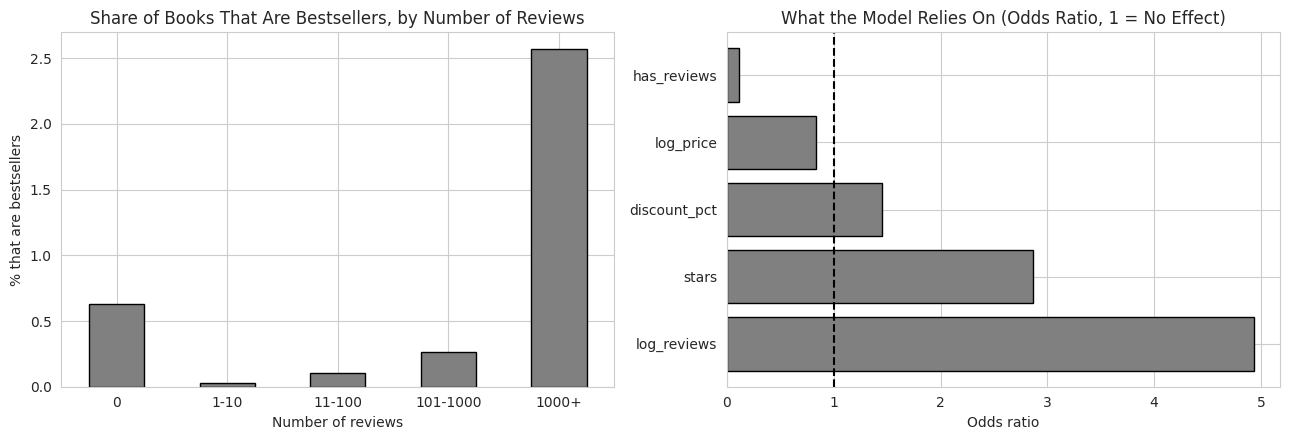

In [57]:
# Client-friendly summary visual: what separates bestsellers, and what the model relies on
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

review_rate.plot(kind="bar", color="gray", edgecolor="black", ax=axes[0])
axes[0].set_title("Share of Books That Are Bestsellers, by Number of Reviews")
axes[0].set_xlabel("Number of reviews")
axes[0].set_ylabel("% that are bestsellers")
axes[0].tick_params(axis="x", rotation=0)

axes[1].barh(coef_table["feature"], coef_table["odds_ratio"], color="gray", edgecolor="black")
axes[1].axvline(1, color="black", linestyle="--")
axes[1].set_title("What the Model Relies On (Odds Ratio, 1 = No Effect)")
axes[1].set_xlabel("Odds ratio")

plt.tight_layout()
plt.show()

In [58]:
#@title Comment
say(f"""- **Reviews:** the bestseller rate moves from {rr.iloc[0]:.2f}% for books in the lowest review band ({rr.index[0]}) to {rr.iloc[-1]:.2f}% for books in the highest ({rr.index[-1]}).
- **Price:** the bestseller rate across price bands ranges from {pr.min():.2f}% to {pr.max():.2f}%, and bestsellers have a median price of {med_price[1]:.2f} against {med_price[0]:.2f} for other books.
- **Category:** among the largest categories the bestseller rate runs from {lo_cat:.2f}% to {hi_cat:.2f}%.
- **Rarity:** only {share_books:.2f}% of books are bestsellers, so most books will not be, and the model is built to cope with this.""")

- **Reviews:** the bestseller rate moves from 0.63% for books in the lowest review band (0) to 2.57% for books in the highest (1000+).
- **Price:** the bestseller rate across price bands ranges from 0.42% to 0.76%, and bestsellers have a median price of 18.49 against 19.99 for other books.
- **Category:** among the largest categories the bestseller rate runs from 0.07% to 1.16%.
- **Rarity:** only 0.61% of books are bestsellers, so most books will not be, and the model is built to cope with this.

### 5.4 How the Model Works

The model gives each book a score based on its features and turns that score into a probability between 0 and 1. It learns by repeatedly checking how wrong its probabilities are and nudging each feature's importance in the direction that reduces the error. I wrote this process myself using only basic maths, so every step can be explained and audited.

### 5.5 How I Ensured the Model Is Accurate and Effective

In [59]:
#@title Comment
check_text = ("Results closely match scikit-learn's own implementation" if max_diff < 0.2
              else "Results were compared with scikit-learn's own implementation")

say(f"""| **Safeguard** | **What It Does** |
|:---|:---|
| Three-way split | Training teaches the model, validation tunes it, and the test set is used once for an honest score |
| Scaling on training data only | Stops information from the test set leaking into training |
| Leakage check | Removes a feature that would not be known before launch and gives away the result |
| Imbalance handling | Class weights and a tuned threshold so the model does not ignore bestsellers |
| Right metrics | Precision, recall, F1 and ROC-AUC instead of accuracy alone |
| Independent check | {check_text} |
| Overfitting check | Training and test F1 differ by {gap_f1:.3f} |""")

| **Safeguard** | **What It Does** |
|:---|:---|
| Three-way split | Training teaches the model, validation tunes it, and the test set is used once for an honest score |
| Scaling on training data only | Stops information from the test set leaking into training |
| Leakage check | Removes a feature that would not be known before launch and gives away the result |
| Imbalance handling | Class weights and a tuned threshold so the model does not ignore bestsellers |
| Right metrics | Precision, recall, F1 and ROC-AUC instead of accuracy alone |
| Independent check | Results closely match scikit-learn's own implementation |
| Overfitting check | Training and test F1 differ by -0.007 |

### 5.6 How Well the Model Performs

In [60]:
#@title Comment
say(f"""| **Metric** | **Baseline Model (Validation)** | **Tuned Model (Validation)** | **Tuned Model (Test)** |
|:---|:---|:---|:---|
| Precision | {metrics_1['precision']:.3f} | {metrics_2['precision']:.3f} | {test_metrics['precision']:.3f} |
| Recall | {metrics_1['recall']:.3f} | {metrics_2['recall']:.3f} | {test_metrics['recall']:.3f} |
| F1 | {metrics_1['f1']:.3f} | {metrics_2['f1']:.3f} | {test_metrics['f1']:.3f} |
| ROC-AUC | {metrics_1['auc']:.3f} | {metrics_2['auc']:.3f} | {test_metrics['auc']:.3f} |

The baseline model reached an accuracy of {100 * metrics_1['accuracy']:.2f}% but found only {100 * metrics_1['recall']:.1f}% of the bestsellers, because it predicted "not a bestseller" for nearly every book. I improved it with class weights, a regularisation penalty and a tuned decision threshold, which moved recall from {metrics_1['recall']:.3f} to {metrics_2['recall']:.3f} on the validation set.""")

| **Metric** | **Baseline Model (Validation)** | **Tuned Model (Validation)** | **Tuned Model (Test)** |
|:---|:---|:---|:---|
| Precision | 0.000 | 0.053 | 0.050 |
| Recall | 0.000 | 0.132 | 0.132 |
| F1 | 0.000 | 0.075 | 0.073 |
| ROC-AUC | 0.691 | 0.730 | 0.765 |

The baseline model reached an accuracy of 99.39% but found only 0.0% of the bestsellers, because it predicted "not a bestseller" for nearly every book. I improved it with class weights, a regularisation penalty and a tuned decision threshold, which moved recall from 0.000 to 0.132 on the validation set.

### 5.7 Recommendations

In [61]:
#@title Comment
say(f"""1. Use the model as a shortlisting tool, for example to flag titles with bestseller potential for extra marketing.
2. Monitor the **{plain_name(top_feature)}** closely after launch, since it is the strongest signal in the model.
3. Add author, publisher, page count and publication date to the data, because the current model cannot see them.
4. Re-train the model regularly, because bestseller patterns change over time.""")

1. Use the model as a shortlisting tool, for example to flag titles with bestseller potential for extra marketing.
2. Monitor the **whether a book has any reviews** closely after launch, since it is the strongest signal in the model.
3. Add author, publisher, page count and publication date to the data, because the current model cannot see them.
4. Re-train the model regularly, because bestseller patterns change over time.

### 5.8 Limitations

In [62]:
#@title Comment
scope_limit = ("- The book categories alone had too few bestsellers, so the model uses all product categories and may behave differently for books specifically."
               if filter_level == "all product categories" else "")
say(f"""- The data is one snapshot from one platform, so results may not hold for other retailers or periods.
- Reviews and ratings only exist after launch, so this is an early-signal model and not a pre-launch forecast.
- Content-based drivers such as author, genre detail and cover are not in the data.
- The test set contains only {int(y_test.sum()):,} bestsellers, so the test scores carry some uncertainty.
- A stratified sample of {len(model_df):,} books was used for modelling.
{scope_limit}""")

- The data is one snapshot from one platform, so results may not hold for other retailers or periods.
- Reviews and ratings only exist after launch, so this is an early-signal model and not a pre-launch forecast.
- Content-based drivers such as author, genre detail and cover are not in the data.
- The test set contains only 91 bestsellers, so the test scores carry some uncertainty.
- A stratified sample of 100,000 books was used for modelling.
- The book categories alone had too few bestsellers, so the model uses all product categories and may behave differently for books specifically.

# 6 Conclusion

## 6.1 Summary of Methodology

This assignment built a logistic regression model from scratch to predict whether a book will be a bestseller, using book products from the Amazon Products Dataset.

| Stage | Method Applied |
|---|---|
| Dataset | Amazon Products Dataset, filtered to book categories |
| Data Cleaning | Duplicates dropped, zero prices removed, list price filled, unrated books flagged |
| EDA | Class balance, distributions by class, bestseller rate by band, leakage check, correlation heatmap |
| Leakage Control | `boughtinlastmonth` excluded |
| Feature Engineering | Log price, log reviews, discount percentage, flags, category dummies |
| Data Split | Stratified 70/15/15 train, validation and test |
| Feature Selection | Standardisation, VIF check, backward elimination at p > 0.05, forward selection cross-check |
| Model | Logistic regression with gradient descent written in NumPy |
| Retraining | Balanced class weights, L2 penalty, tuned learning rate and threshold |
| Evaluation | Confusion matrix, precision, recall, F1, ROC-AUC, precision-recall curve, scikit-learn cross-check and benchmark, overfitting check |
| Interpretation | Odds ratios |
| Client Report | Plain-language report with visuals, recommendations and limitations |

In [63]:
#@title Comment
say(f"""The tuned model was trained on {len(y_train):,} books and achieved an F1 of {test_metrics['f1']:.3f}, a recall of {test_metrics['recall']:.3f}, a precision of {test_metrics['precision']:.3f} and a ROC-AUC of {test_metrics['auc']:.3f} on the unseen test set, with a training and test F1 gap of {gap_f1:.3f}. The most influential feature was the {plain_name(top_feature)}.""")

The tuned model was trained on 70,000 books and achieved an F1 of 0.073, a recall of 0.132, a precision of 0.050 and a ROC-AUC of 0.765 on the unseen test set, with a training and test F1 gap of -0.007. The most influential feature was the whether a book has any reviews.

## 6.2 Final Closing Statement

This assignment combined a logistic regression written from scratch with careful data preparation, a leakage and imbalance strategy, and an evaluation that was verified against scikit-learn. The result is a transparent and explainable model that the book press can audit, together with a plain-language report that translates the technical work into decisions the press can act on. The findings, recommendations and limitations are set out in section 5.

# 7 Reference List

Asaniczka (2023) *Amazon Products Dataset 2023 (1.4M Products)* [Dataset]. Kaggle. Available at: https://www.kaggle.com/datasets/asaniczka/amazon-products-dataset-2023-1-4m-products (Accessed: 22 October 2026).

Fawcett, T. (2006) 'An introduction to ROC analysis', *Pattern Recognition Letters*, 27(8), pp. 861-874.

Harris, C.R., Millman, K.J., van der Walt, S.J. et al. (2020) 'Array programming with NumPy', *Nature*, 585(7825), pp. 357-362.

Hastie, T., Tibshirani, R. and Friedman, J. (2009) *The Elements of Statistical Learning: Data Mining, Inference, and Prediction*. 2nd edn. New York: Springer.

He, H. and Garcia, E.A. (2009) 'Learning from imbalanced data', *IEEE Transactions on Knowledge and Data Engineering*, 21(9), pp. 1263-1284.

Hosmer, D.W., Lemeshow, S. and Sturdivant, R.X. (2013) *Applied Logistic Regression*. 3rd edn. Hoboken: John Wiley and Sons.

Hunter, J.D. (2007) 'Matplotlib: a 2D graphics environment', *Computing in Science and Engineering*, 9(3), pp. 90-95.

Kaufman, S., Rosset, S., Perlich, C. and Stitelman, O. (2012) 'Leakage in data mining: formulation, detection, and avoidance', *ACM Transactions on Knowledge Discovery from Data*, 6(4), Article 15.

McKinney, W. (2010) 'Data structures for statistical computing in Python', *Proceedings of the 9th Python in Science Conference*, pp. 56-61.

Ng, A.Y. (2004) 'Feature selection, L1 vs L2 regularization, and rotational invariance', *Proceedings of the 21st International Conference on Machine Learning (ICML)*, pp. 78-85.

O'Brien, R.M. (2007) 'A caution regarding rules of thumb for variance inflation factors', *Quality and Quantity*, 41(5), pp. 673-690.

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M. and Duchesnay, E. (2011) 'Scikit-learn: Machine Learning in Python', *Journal of Machine Learning Research*, 12, pp. 2825-2830.

Republic of South Africa (2013) *Protection of Personal Information Act (POPIA), Act No. 4 of 2013*. Pretoria: Government Gazette. Available at: https://www.gov.za/documents/protection-personal-information-act (Accessed: 22 October 2026).

Saito, T. and Rehmsmeier, M. (2015) 'The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets', *PLoS ONE*, 10(3), e0118432.

Seabold, S. and Perktold, J. (2010) 'Statsmodels: econometric and statistical modeling with Python', *Proceedings of the 9th Python in Science Conference*, pp. 92-96.

Waskom, M.L. (2021) 'seaborn: statistical data visualization', *Journal of Open Source Software*, 6(60), Article 3021.